# <font color = "red">**Day 24: Physics-Informed Learning from Atomic-Resolution Microscopy**</font>

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/kbarakati/athena_camm_hackathon/blob/k4my4r/docs/day_24_11062026/reward_driven_image_analysis.ipynb)

**Challenge Overview**

Atomic-resolution scanning transmission electron microscopy (STEM) provides detailed information about the local structure of crystalline materials. However, extracting physically meaningful properties from microscopy images often requires specialized analysis, atomic-scale measurements, and knowledge of the underlying material structure.

**<font color = "blue">The goal of this challenge is to develop physics-informed algorithms that extract local material properties directly from high-angle annular dark-field (HAADF-STEM) images.</font>**

Participants will work with atomic-resolution images of Sm-doped BiFeO₃ (Sm-BFO) at different compositions (0%, 7%, 10%, 13%, and 20% Sm).

- The primary objective is to reconstruct spatial maps of local polarization-related atomic displacements using image analysis, machine learning, or physics-guided computational methods.

**Participants may use:**

1. HAADF images: Raw atomic-resolution microscopy images.

2. Atomic coordinates (xy_atms): Positions of detected atomic columns.

3. Unit-cell coordinates (xy_COM): Reference positions associated with individual unit cells.

4. Structural parameters: Lattice parameters, unit-cell geometry, and other non-target structural descriptors.

5. Material information: Sm composition and relevant crystallographic knowledge.

Participants may combine these inputs with physical models, computer vision, statistical methods, or machine learning to reconstruct local material properties.

<font color = "red">**Ground Truth and Restrictions**</font>

Reference polarization-related displacement maps **(Pxy)** are provided for verification and evaluation only.

- Participants must not use these reference values as inputs to their algorithms, for model training, or for selecting and optimizing model parameters.

- The reference data may only be used after generating predictions to evaluate the agreement between reconstructed and reference maps.

- Any additional property used as an input must not directly encode or reproduce the reference polarization values.

### load data

In [ ]:
import os
import h5py
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
! gdown --folder "https://drive.google.com/drive/folders/1fXwChjwMT9PH5YtonZoDG3kXVL6mfEQg?usp=sharing"

Retrieving folder contents
Processing file 1t9UEszmi8g5UiUpxvgY68cF52MxZIPi7 Copy of Sm_0_1_HAADF.h5
Processing file 1w8JJIwxR0WafWwukEVtdCJKPxWoQz5Ob Copy of Sm_0_1_UCParameterization.h5
Processing file 14ausdfP5FDJmHBWFftZC1KwuErdIG50e Copy of Sm_7_3_HAADF.h5
Processing file 1CymqlhlBuh4pWPnQphqRrBHKyO2d2S_o Copy of Sm_7_3_UCParameterization.h5
Processing file 1Lif7rAJ_soAnuwp861wLXUjccxKOzbKI Copy of Sm_10_1_HAADF.h5
Processing file 1e5GGvxP6Wvo7NhLhrB7Vh0R-SeAxRf1_ Copy of Sm_10_1_UCParameterization.h5
Processing file 1dB5yNghQeNN-5Ca-nETArSr_UZ7I3kXr Copy of Sm_13_1_HAADF.h5
Processing file 13DvtGZ9gGklhSm5J8a2VZVTeAj5SiBJG Copy of Sm_13_1_UCParameterization.h5
Processing file 1l8TObek8BiAxRyy6vx7Ea1Kq54I_o7RV Copy of Sm_20_1_HAADF.h5
Processing file 1VZvrpKVG0hz5hxpoqTJdFhBkbxu-w-t3 Copy of Sm_20_1_UCParameterization.h5
Retrieving folder contents completed
Building directory structure
Building directory structure completed
Downloading...
From (original): https://drive.google.com/

In [ ]:
#list files
filedir = 'data_small'
[f for f in os.listdir(filedir)]

['Copy of Sm_13_1_HAADF.h5',
 'Copy of Sm_7_3_UCParameterization.h5',
 'Copy of Sm_10_1_HAADF.h5',
 'Copy of Sm_10_1_UCParameterization.h5',
 'Copy of Sm_7_3_HAADF.h5',
 'Copy of Sm_20_1_HAADF.h5',
 'Copy of Sm_13_1_UCParameterization.h5',
 'Copy of Sm_20_1_UCParameterization.h5',
 'Copy of Sm_0_1_HAADF.h5',
 'Copy of Sm_0_1_UCParameterization.h5']

In [ ]:
# Find HAADF images
img_filename = sorted(
    f for f in os.listdir(filedir) if f.endswith("_HAADF.h5")
)

# Match parameterization files
UCparam_filename = [
    f.replace("_HAADF.h5", "_UCParameterization.h5")
    for f in img_filename
]

# Extract Sm composition (%)
composition_tags = [
    int(f.replace("Copy of ", "").split("_")[1])
    for f in img_filename
]

# Load datasets
imgdata = [
    np.asarray(h5py.File(os.path.join(filedir, f), "r")["MainImage"])
    for f in img_filename
]

UCparam = [
    h5py.File(os.path.join(filedir, f), "r")
    for f in UCparam_filename
]

imnum = len(imgdata)

print(f"Loaded {imnum} images and parameterization files")
print("Sm compositions (%):", composition_tags)
print("UC parameters:", list(UCparam[0].keys()))


Loaded 5 images and parameterization files
Sm compositions (%): [0, 10, 13, 20, 7]
UC parameters: ['I1', 'I2', 'I3', 'I4', 'I5', 'NCOM', 'PCOM', 'Pxy', 'Vol', 'a', 'ab', 'abdelta', 'alpha', 'atmindex', 'b', 'index', 'meanuca', 'meanucb', 'nbrUC', 'xy_COM', 'xy_atms']


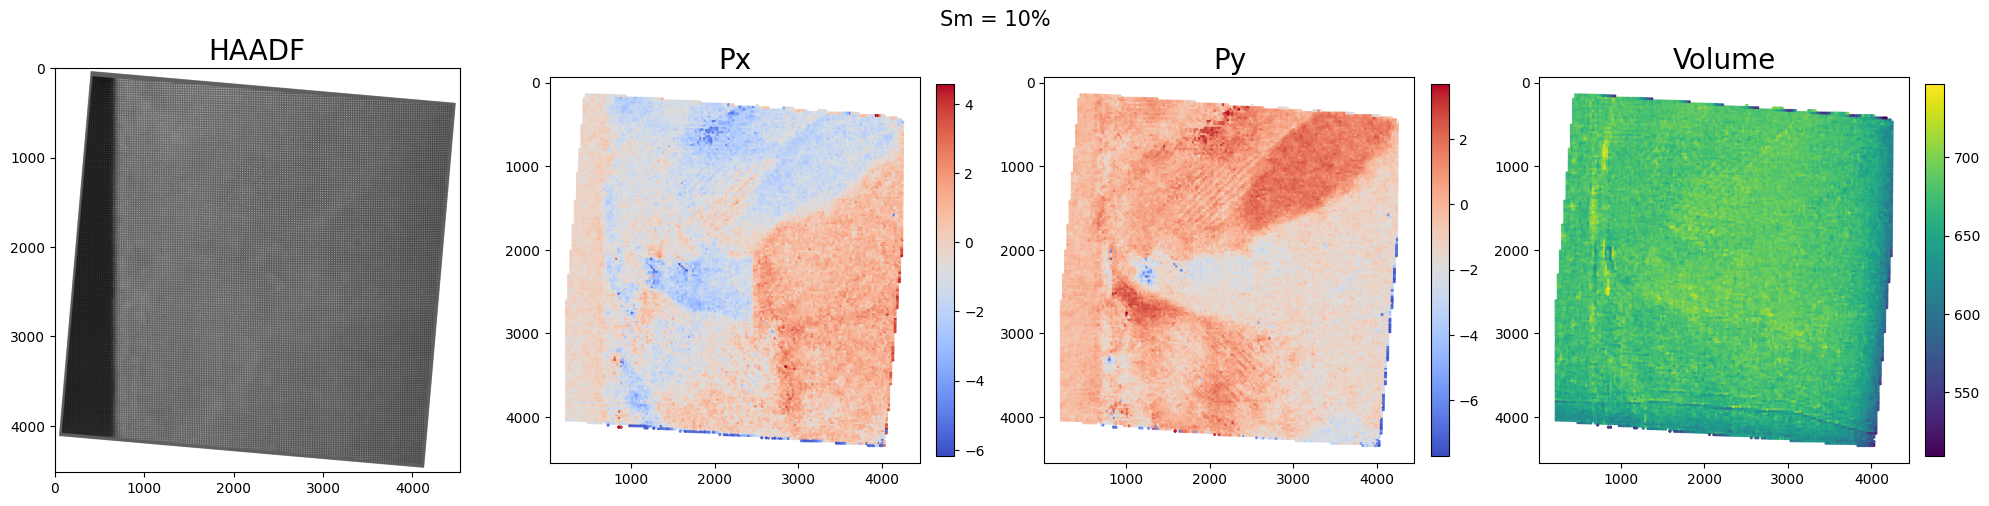

In [ ]:
idx = 1

# Load data
img = np.asarray(imgdata[idx]).squeeze()
pxy = np.asarray(UCparam[idx]["Pxy"]).T
vol = np.asarray(UCparam[idx]["Vol"]).ravel()
xy = np.asarray(UCparam[idx]["xy_COM"]).T

# Extract polarization components
px, py = pxy[:, 0], pxy[:, 1]

# Plot HAADF and unit-cell parameters
fig, axes = plt.subplots(1, 4, figsize=(20, 5))

axes[0].imshow(img, cmap="gray")
axes[0].set_title("HAADF", fontsize =20)

for ax, data, title, cmap in zip(
    axes[1:],
    [px, py, vol],
    ["Px", "Py", "Volume"],
    ["coolwarm", "coolwarm", "viridis"]
):
    im = ax.scatter(
        xy[:, 1], xy[:, 0],
        c=data, cmap=cmap, s=5, marker="o", linewidths=0
    )
    ax.invert_yaxis()
    ax.set_title(title, fontsize =20)
    ax.set_aspect("equal")
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

# for ax in axes:
#     ax.axis("off")

fig.suptitle(f"Sm = {composition_tags[idx]}%", fontsize=15)
plt.tight_layout()
plt.show()


<font color = "red">**Look Closer**</font>

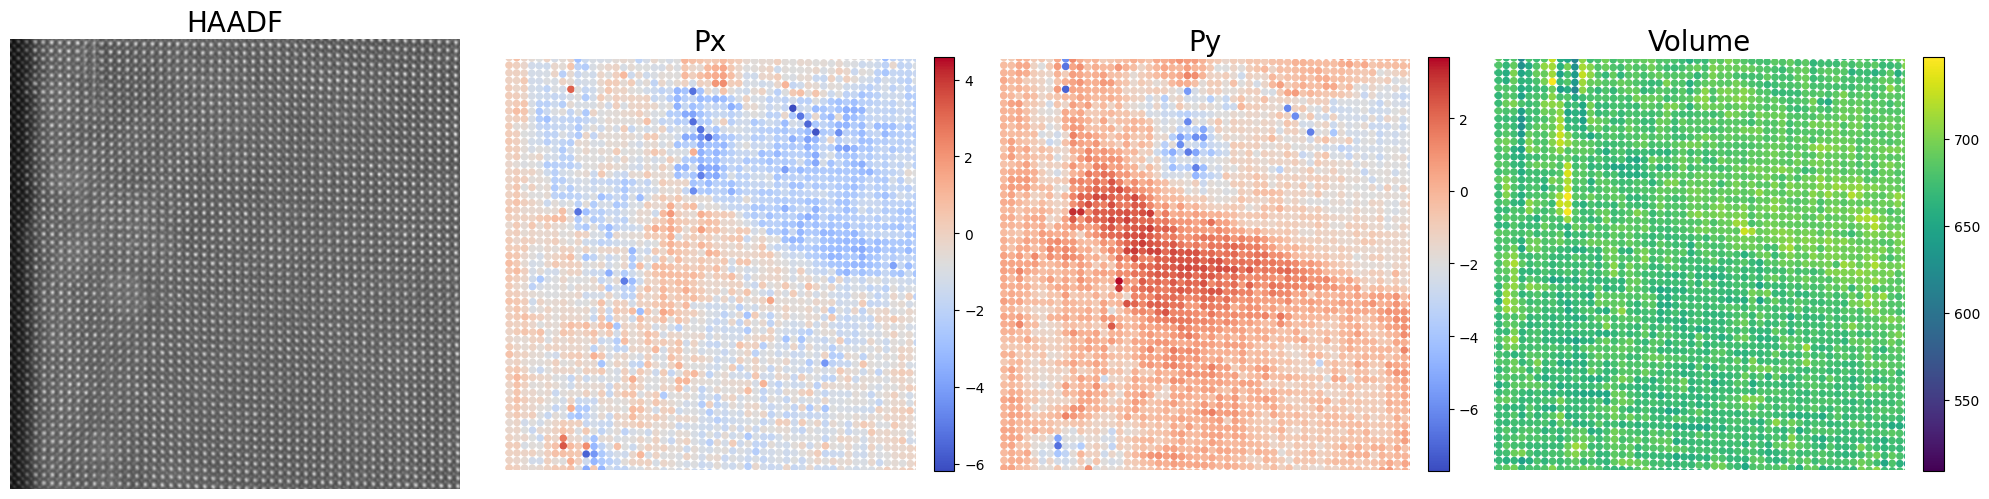

In [ ]:
# Select region (image pixel coordinates)
xlim = (600, 2000)
ylim = (2000, 3400)

fig, axes = plt.subplots(1, 4, figsize=(20, 5))

axes[0].imshow(img, cmap="gray")
axes[0].set_title("HAADF", fontsize = 20)

for ax, data, title, cmap in zip(
    axes[1:],
    [px, py, vol],
    ["Px", "Py", "Volume"],
    ["coolwarm", "coolwarm", "viridis"]
):
    im = ax.scatter(
        xy[:, 1], xy[:, 0],
        c=data, cmap=cmap, s=30, marker="o", linewidths=0
    )
    ax.set_title(title, fontsize = 20)
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

for ax in axes:
    ax.set_xlim(*xlim)
    ax.set_ylim(ylim[1], ylim[0])
    ax.set_aspect("equal")
    ax.axis("off")

plt.tight_layout()
plt.show()


<font color = "red">**atom cordinates and center of the mass**</font>

Original shape: (2, 5, 22949)


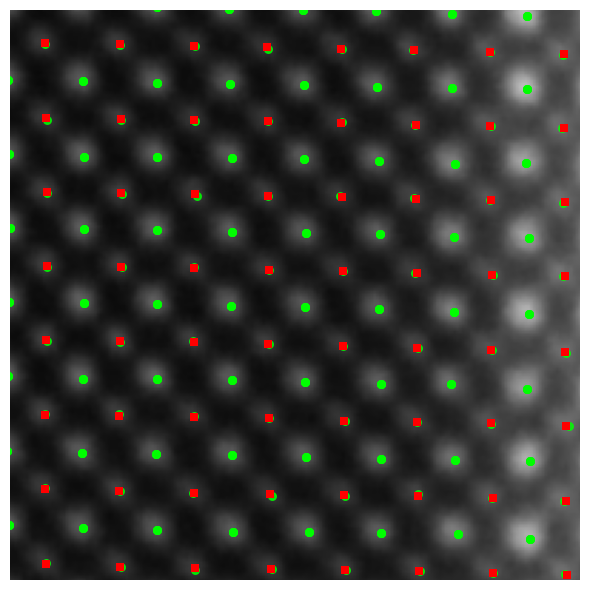

In [ ]:
xlim = (500, 700)
ylim = (500, 700)

xy_atms = np.asarray(UCparam[idx]["xy_atms"]).squeeze()

xy = np.asarray(UCparam[idx]["xy_COM"]).T

print("Original shape:", xy_atms.shape)

# Convert coordinates into (N, 2)
if xy_atms.shape[-1] == 2:
    coords = xy_atms.reshape(-1, 2)
elif xy_atms.shape[0] == 2:
    coords = xy_atms.reshape(2, -1).T
else:
    raise ValueError("Inspect xy_atms structure before plotting")

fig, ax = plt.subplots(figsize=(6, 6))

ax.imshow(img, cmap="gray")

ax.scatter(
    coords[:, 1], coords[:, 0],
    s=30, c="lime", alpha=0.8
)

ax.scatter(
    xy[:, 1], xy[:, 0],
    s=30, c="red", marker="s", linewidths=0
)

ax.set_xlim(*xlim)
ax.set_ylim(ylim[1], ylim[0])
ax.set_aspect("equal")
ax.axis("off")

plt.tight_layout()
plt.show()

<font color = "red">**Unit cell**</font>

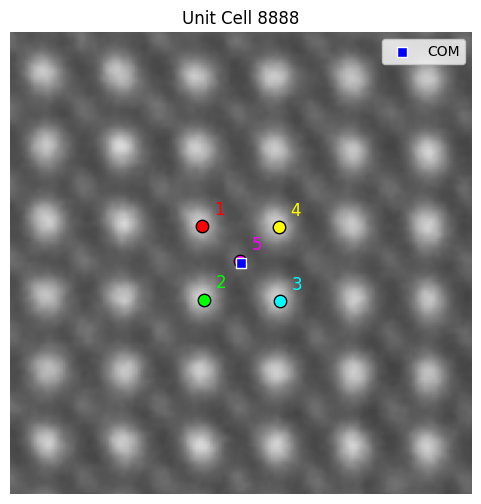

In [ ]:
cell = 8888

fig, ax = plt.subplots(figsize=(6, 6))
ax.imshow(img, cmap="gray")

colors = ["red", "lime", "cyan", "yellow", "magenta"]
atoms = np.asarray(UCparam[idx]["xy_atms"])
com = np.asarray(UCparam[idx]["xy_COM"])

# Plot five atomic positions
for i in range(5):
    y, x = atoms[:, i, cell]
    ax.scatter(x, y, s=80, c=colors[i], edgecolors="black")
    ax.text(x + 4, y - 4, str(i + 1), color=colors[i], fontsize=12)

# Plot center of mass
y_com, x_com = com[:, cell]
ax.scatter(x_com, y_com, s=60, c="blue",
           marker="s", edgecolors="white", label="COM")

# Zoom around the unit cell
x_center = atoms[1, :, cell].mean()
y_center = atoms[0, :, cell].mean()

ax.set_xlim(x_center - 80, x_center + 80)
ax.set_ylim(y_center + 80, y_center - 80)
ax.set_title(f"Unit Cell {cell}")
ax.legend()
ax.set_axis_off()

plt.show()

<font color = "red">**Polarization**</font>

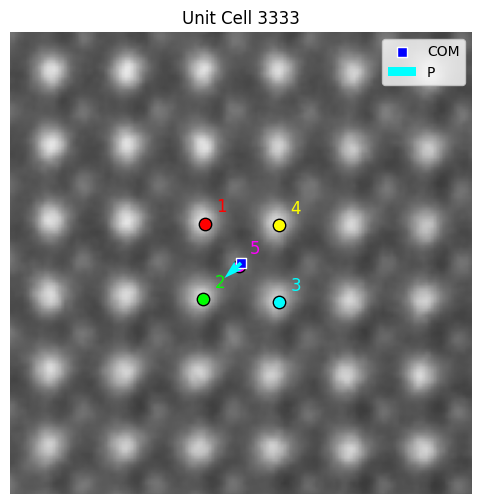

In [ ]:
cell = 3333

fig, ax = plt.subplots(figsize=(6, 6))
ax.imshow(img, cmap="gray")

colors = ["red", "lime", "cyan", "yellow", "magenta"]
atoms = np.asarray(UCparam[idx]["xy_atms"])
com = np.asarray(UCparam[idx]["xy_COM"])
pxy = np.asarray(UCparam[idx]["Pxy"])

# Plot five atomic positions
for i in range(5):
    y, x = atoms[:, i, cell]
    ax.scatter(x, y, s=80, c=colors[i], edgecolors="black")
    ax.text(x + 4, y - 4, str(i + 1), color=colors[i], fontsize=12)

# Plot center of mass
y_com, x_com = com[:, cell]
ax.scatter(x_com, y_com, s=60, c="blue",
           marker="s", edgecolors="white", label="COM")

# Plot polarization components
px, py = pxy[:, cell]

scale = 5  # Arrow magnification
ax.quiver(
    x_com, y_com,
    px * scale, py * scale,
    color="cyan",
    angles="xy", scale_units="xy", scale=1,
    width=0.008, label="P"
)

# Zoom
x_center = atoms[1, :, cell].mean()
y_center = atoms[0, :, cell].mean()

ax.set_xlim(x_center - 80, x_center + 80)
ax.set_ylim(y_center + 80, y_center - 80)
ax.set_aspect("equal")
ax.set_title(f"Unit Cell {cell}")
ax.legend()
ax.set_axis_off()

plt.show()

<font color = "tomato">**Challenge Objectives**</font>

The primary task is to reconstruct the two in-plane components of the local polarization proxy, $P_x$ and $P_y$, and generate spatial maps showing their magnitude and direction.

Participants are encouraged to explore different approaches, including:

- Physics-informed analysis: Use atomic positions, local symmetry, and lattice distortions to estimate polarization-related displacements.

- Computer vision and machine learning: Develop methods to identify structural features and predict local properties from microscopy images.

- Advanced or hybrid approaches: Combine physical constraints, statistical modeling, and learned representations to improve the robustness and accuracy of reconstruction.

<font color = "plum">**Important**</font>
* Participants may also investigate additional properties, such as lattice distortion, local strain, structural heterogeneity, or domain boundaries.

<font color = "navy">**Expected Outcomes**</font>

Participants should submit:

- A reproducible Python workflow or Jupyter notebook.

- Reconstructed spatial maps of $P_x$, $P_y$, and polarization-proxy magnitude or orientation.

- Quantitative comparison with the provided reference maps.

- A short explanation of the physical assumptions, methodology, and limitations.

<font color = "magenta">**Central Scientific Question**</font>


Can we develop physics-informed computational methods that reconstruct local polarization-related properties from atomic-resolution microscopy data without relying on precomputed polarization labels?

INPUT CHECK — no reference polarization values are read
Coordinate convention: row first, column second; no indexing shift applied.

Sm_0_1 | Sm = 0% | image = (4454, 4405) | cells = 23,541
  Original shapes: xy_atms (2, 5, 23541), xy_COM (2, 23541)
  All five atoms finite: 23,541/23,541
  All five atoms finite and in image: 23,541/23,541
  xy_COM finite and in image: 23,541/23,541
  Most-central position: atom 1: 0.0%, atom 2: 0.0%, atom 3: 0.0%, atom 4: 0.0%, atom 5: 100.0%

Sm_7_3 | Sm = 7% | image = (4474, 4492) | cells = 23,074
  Original shapes: xy_atms (2, 5, 23074), xy_COM (2, 23074)
  All five atoms finite: 23,074/23,074
  All five atoms finite and in image: 23,074/23,074
  xy_COM finite and in image: 23,074/23,074
  Most-central position: atom 1: 0.0%, atom 2: 0.0%, atom 3: 0.0%, atom 4: 0.0%, atom 5: 100.0%

Sm_10_1 | Sm = 10% | image = (4520, 4527) | cells = 22,949
  Original shapes: xy_atms (2, 5, 22949), xy_COM (2, 22949)
  All five atoms finite: 22,949/22,949
  All five 

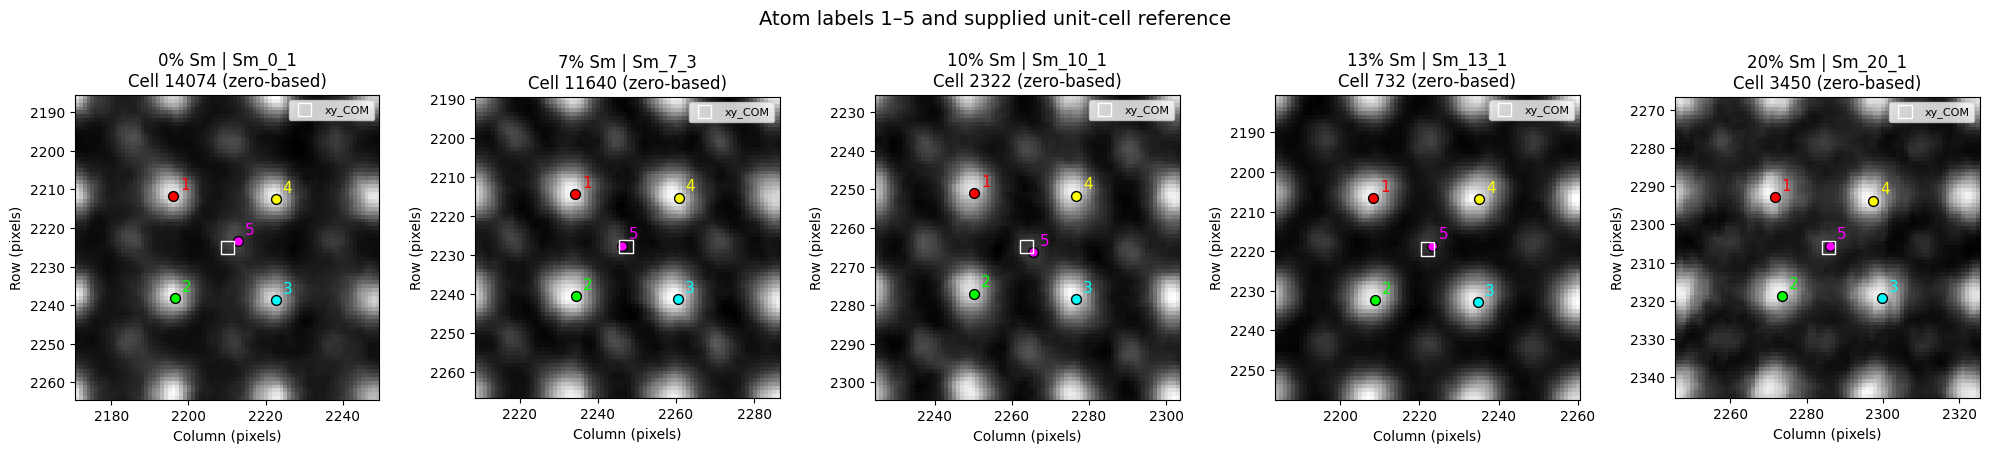

AVAILABLE METADATA
(File attributes and allowed-array attributes only)
Sm_0_1: No attributes found.
Sm_7_3: No attributes found.
Sm_10_1: No attributes found.
Sm_13_1: No attributes found.
Sm_20_1: No attributes found.

Loaded compositions: [0, 7, 10, 13, 20]

Block 1 complete. Inputs are stored in hackathon_samples.
No chemical identities, displacement sign, or physical-unit conversion assumed.


In [ ]:
# BLOCK 1 — Load allowed inputs and inspect the five-atom geometry.
# Reads MainImage, xy_atms, and xy_COM only. Does not read Pxy.

from pathlib import Path
import re
import h5py
import numpy as np
import matplotlib.pyplot as plt

# Reuses the starter notebook's folder. Edit this line if your data are elsewhere.
HA_DATA_DIR = Path(globals().get("filedir", "data_small")).expanduser()

if not HA_DATA_DIR.is_dir():
    raise FileNotFoundError(
        f"Data folder not found: {HA_DATA_DIR.resolve()}\n"
        "Set HA_DATA_DIR to the folder containing the downloaded .h5 files."
    )

# Find and pair the image and parameterization files.
ha_pairs = []

for ha_path in HA_DATA_DIR.glob("*_HAADF.h5"):
    ha_match = re.search(r"Sm_(\d+)_(\d+)_HAADF\.h5$", ha_path.name)

    if ha_match is None:
        raise ValueError(f"Unrecognized specimen filename: {ha_path.name}")

    ha_sm, ha_rep = map(int, ha_match.groups())

    ha_uc_path = ha_path.with_name(
        ha_path.name.replace("_HAADF.h5", "_UCParameterization.h5")
    )

    if not ha_uc_path.is_file():
        raise FileNotFoundError(f"Missing paired file: {ha_uc_path.name}")

    ha_pairs.append((ha_sm, ha_rep, ha_path, ha_uc_path))

ha_pairs.sort(key=lambda item: (item[0], item[1]))

if not ha_pairs:
    raise FileNotFoundError(
        f"No *_HAADF.h5 files found in {HA_DATA_DIR.resolve()}"
    )

if len({(p[0], p[1]) for p in ha_pairs}) != len(ha_pairs):
    raise ValueError(
        "Duplicate specimen IDs found. Keep one file pair per specimen."
    )


def ha_atoms_to_rc(raw):
    """Return (cells, 5 atoms, 2 coordinates), ordered as (row, column)."""
    a = np.asarray(raw, dtype=float)

    if a.ndim == 3 and a.shape[:2] == (2, 5):
        return a.transpose(2, 1, 0)  # (2, 5, N) -> (N, 5, 2)

    if a.ndim == 3 and a.shape[1:] == (5, 2):
        return a

    raise ValueError(
        f"Unexpected xy_atms shape: {a.shape}; inspect before continuing."
    )


def ha_com_to_rc(raw, n_cells):
    """Return unit-cell reference coordinates as (cells, row/column)."""
    a = np.asarray(raw, dtype=float)

    if a.shape == (2, n_cells):
        return a.T

    if a.shape == (n_cells, 2):
        return a

    raise ValueError(
        f"Unexpected xy_COM shape: {a.shape}; expected {n_cells} cells."
    )


def ha_short_attrs(obj):
    """Read metadata attributes, shortening long values for display."""
    return {str(k): repr(v)[:180] for k, v in obj.attrs.items()}


# These variables will be reused in the next code blocks.
hackathon_samples = []
hackathon_metadata = {}

ha_fig, ha_axes = plt.subplots(
    1,
    len(ha_pairs),
    figsize=(4 * len(ha_pairs), 4.6),
    squeeze=False,
)

print("INPUT CHECK — no reference polarization values are read")
print(
    "Coordinate convention: row first, column second; "
    "no indexing shift applied.\n"
)

for ha_ax, (ha_sm, ha_rep, ha_path, ha_uc_path) in zip(
    ha_axes.ravel(), ha_pairs
):
    ha_id = f"Sm_{ha_sm}_{ha_rep}"

    # Read only the explicitly allowed arrays.
    with h5py.File(ha_path, "r") as ha_imf, h5py.File(
        ha_uc_path, "r"
    ) as ha_ucf:
        ha_image = np.asarray(ha_imf["MainImage"]).squeeze()
        ha_raw_atoms = np.asarray(ha_ucf["xy_atms"])
        ha_raw_com = np.asarray(ha_ucf["xy_COM"])

        hackathon_metadata[ha_id] = {
            "image_file": ha_short_attrs(ha_imf),
            "MainImage": ha_short_attrs(ha_imf["MainImage"]),
            "parameter_file": ha_short_attrs(ha_ucf),
            "xy_atms": ha_short_attrs(ha_ucf["xy_atms"]),
            "xy_COM": ha_short_attrs(ha_ucf["xy_COM"]),
        }

    if ha_image.ndim != 2:
        raise ValueError(
            f"{ha_id}: MainImage is not 2D after squeezing: "
            f"{ha_image.shape}"
        )

    ha_h, ha_w = ha_image.shape
    ha_atoms = ha_atoms_to_rc(ha_raw_atoms)
    ha_n = len(ha_atoms)
    ha_com = ha_com_to_rc(ha_raw_com, ha_n)

    # Check whether each cell has five finite, in-bounds atomic positions.
    ha_finite = np.isfinite(ha_atoms).all(axis=(1, 2))

    ha_bounds = (
        (ha_atoms[:, :, 0] >= 0)
        & (ha_atoms[:, :, 0] < ha_h)
        & (ha_atoms[:, :, 1] >= 0)
        & (ha_atoms[:, :, 1] < ha_w)
    ).all(axis=1)

    ha_valid = ha_finite & ha_bounds

    ha_com_valid = (
        np.isfinite(ha_com).all(axis=1)
        & (ha_com[:, 0] >= 0)
        & (ha_com[:, 0] < ha_h)
        & (ha_com[:, 1] >= 0)
        & (ha_com[:, 1] < ha_w)
    )

    # Keep every original cell and its quality flags.
    # Full images are not retained as additional copies.
    hackathon_samples.append({
        "sample_id": ha_id,
        "sm_percent": ha_sm,
        "image_path": ha_path,
        "parameter_path": ha_uc_path,
        "image_shape": ha_image.shape,
        "atoms_rc": ha_atoms,
        "com_rc": ha_com,
        "cell_ids": np.arange(ha_n),
        "coordinate_valid": ha_valid,
        "com_valid": ha_com_valid,
    })

    print(
        f"{ha_id} | Sm = {ha_sm}% | "
        f"image = {ha_image.shape} | cells = {ha_n:,}"
    )
    print(
        f"  Original shapes: xy_atms {ha_raw_atoms.shape}, "
        f"xy_COM {ha_raw_com.shape}"
    )
    print(f"  All five atoms finite: {ha_finite.sum():,}/{ha_n:,}")
    print(
        f"  All five atoms finite and in image: "
        f"{ha_valid.sum():,}/{ha_n:,}"
    )
    print(
        f"  xy_COM finite and in image: "
        f"{ha_com_valid.sum():,}/{ha_n:,}"
    )

    if not ha_valid.any():
        print(
            "  No valid cell to preview. "
            "Check coordinates and image orientation.\n"
        )
        ha_ax.set_title(f"{ha_id}: no valid cell")
        ha_ax.axis("off")
        del ha_image
        continue

    # Geometric diagnostic only:
    # Which position is closest to the mean of the five positions?
    # This identifies a central-position candidate, not chemical identity.
    ha_good = ha_atoms[ha_valid]
    ha_centroids = ha_good.mean(axis=1)

    ha_distances = np.linalg.norm(
        ha_good - ha_centroids[:, None, :],
        axis=2,
    )

    ha_center_indices = np.argmin(ha_distances, axis=1)
    ha_fractions = (
        np.bincount(ha_center_indices, minlength=5) / len(ha_good)
    )

    print(
        "  Most-central position: "
        + ", ".join(
            f"atom {k + 1}: {100 * fraction:.1f}%"
            for k, fraction in enumerate(ha_fractions)
        )
        + "\n"
    )

    # Select a valid cell near the image center.
    ha_pick = np.argmin(
        np.linalg.norm(
            ha_centroids
            - np.array([(ha_h - 1) / 2, (ha_w - 1) / 2]),
            axis=1,
        )
    )

    ha_cell = np.flatnonzero(ha_valid)[ha_pick]
    ha_points = ha_atoms[ha_cell]
    ha_center = ha_points.mean(axis=0)

    ha_radius = max(
        12.0,
        2 * np.linalg.norm(ha_points - ha_center, axis=1).max(),
    )

    ha_r0 = max(0, int(np.floor(ha_center[0] - ha_radius)))
    ha_r1 = min(ha_h, int(np.ceil(ha_center[0] + ha_radius)) + 1)
    ha_c0 = max(0, int(np.floor(ha_center[1] - ha_radius)))
    ha_c1 = min(ha_w, int(np.ceil(ha_center[1] + ha_radius)) + 1)

    ha_ax.imshow(
        ha_image[ha_r0:ha_r1, ha_c0:ha_c1].copy(),
        cmap="gray",
        origin="upper",
        extent=(
            ha_c0 - 0.5,
            ha_c1 - 0.5,
            ha_r1 - 0.5,
            ha_r0 - 0.5,
        ),
    )

    for ha_k, (ha_row, ha_col) in enumerate(ha_points):
        ha_color = ["red", "lime", "cyan", "yellow", "magenta"][ha_k]

        ha_ax.scatter(
            ha_col,
            ha_row,
            s=50,
            c=ha_color,
            edgecolors="black",
        )

        ha_ax.annotate(
            str(ha_k + 1),
            (ha_col, ha_row),
            xytext=(5, 5),
            textcoords="offset points",
            color=ha_color,
            fontsize=11,
        )

    if ha_com_valid[ha_cell]:
        ha_ax.scatter(
            ha_com[ha_cell, 1],
            ha_com[ha_cell, 0],
            s=90,
            marker="s",
            facecolors="none",
            edgecolors="white",
            label="xy_COM",
        )
        ha_ax.legend(loc="upper right", fontsize=8)

    ha_ax.set_title(
        f"{ha_sm}% Sm | {ha_id}\nCell {ha_cell} (zero-based)"
    )
    ha_ax.set_xlabel("Column (pixels)")
    ha_ax.set_ylabel("Row (pixels)")
    ha_ax.set_aspect("equal")

    del ha_image

ha_fig.suptitle(
    "Atom labels 1–5 and supplied unit-cell reference",
    fontsize=14,
)
ha_fig.tight_layout()
plt.show()

print("AVAILABLE METADATA")
print("(File attributes and allowed-array attributes only)")

for ha_id, ha_sections in hackathon_metadata.items():
    ha_nonempty = {k: v for k, v in ha_sections.items() if v}
    print(
        f"{ha_id}: "
        f"{ha_nonempty if ha_nonempty else 'No attributes found.'}"
    )

ha_found = {s["sm_percent"] for s in hackathon_samples}
print("\nLoaded compositions:", sorted(ha_found))

if ha_found != {0, 7, 10, 13, 20}:
    print(
        "CHECK: the loaded compositions differ from "
        "the five listed in the challenge."
    )

print("\nBlock 1 complete. Inputs are stored in hackathon_samples.")
print(
    "No chemical identities, displacement sign, "
    "or physical-unit conversion assumed."
)

Implementation checks passed: zero offset, known shift, and translation invariance.

GEOMETRIC DISPLACEMENTS — all values below are in pixels
Sample           Valid/total    Mean dx    Mean dy   Median |d|    P95 |d|    Max |d|
Sm_0_1           23541/23541     1.5325    -0.3034       2.7238     6.9123    28.7146
Sm_7_3           23074/23074    -0.1591     0.3965       1.4653     2.4542     9.1007
Sm_10_1          22949/22949     0.3389     0.3477       1.5273     2.9530     8.7935
Sm_13_1          20510/20510     0.2871     0.7264       1.0673     3.4170     8.6398
Sm_20_1          18390/18390     0.6951    -0.3426       1.2201     3.8888     9.8365

LOCATION CHECK — distance between xy_COM and the four-corner center (pixels)
Sm_0_1: median = 0.544766, P95 = 1.382459; mapped cells = 23,541/23,541
Sm_7_3: median = 0.293066, P95 = 0.490843; mapped cells = 23,074/23,074
Sm_10_1: median = 0.305464, P95 = 0.590600; mapped cells = 22,949/22,949
Sm_13_1: median = 0.213469, P95 = 0.683394; map

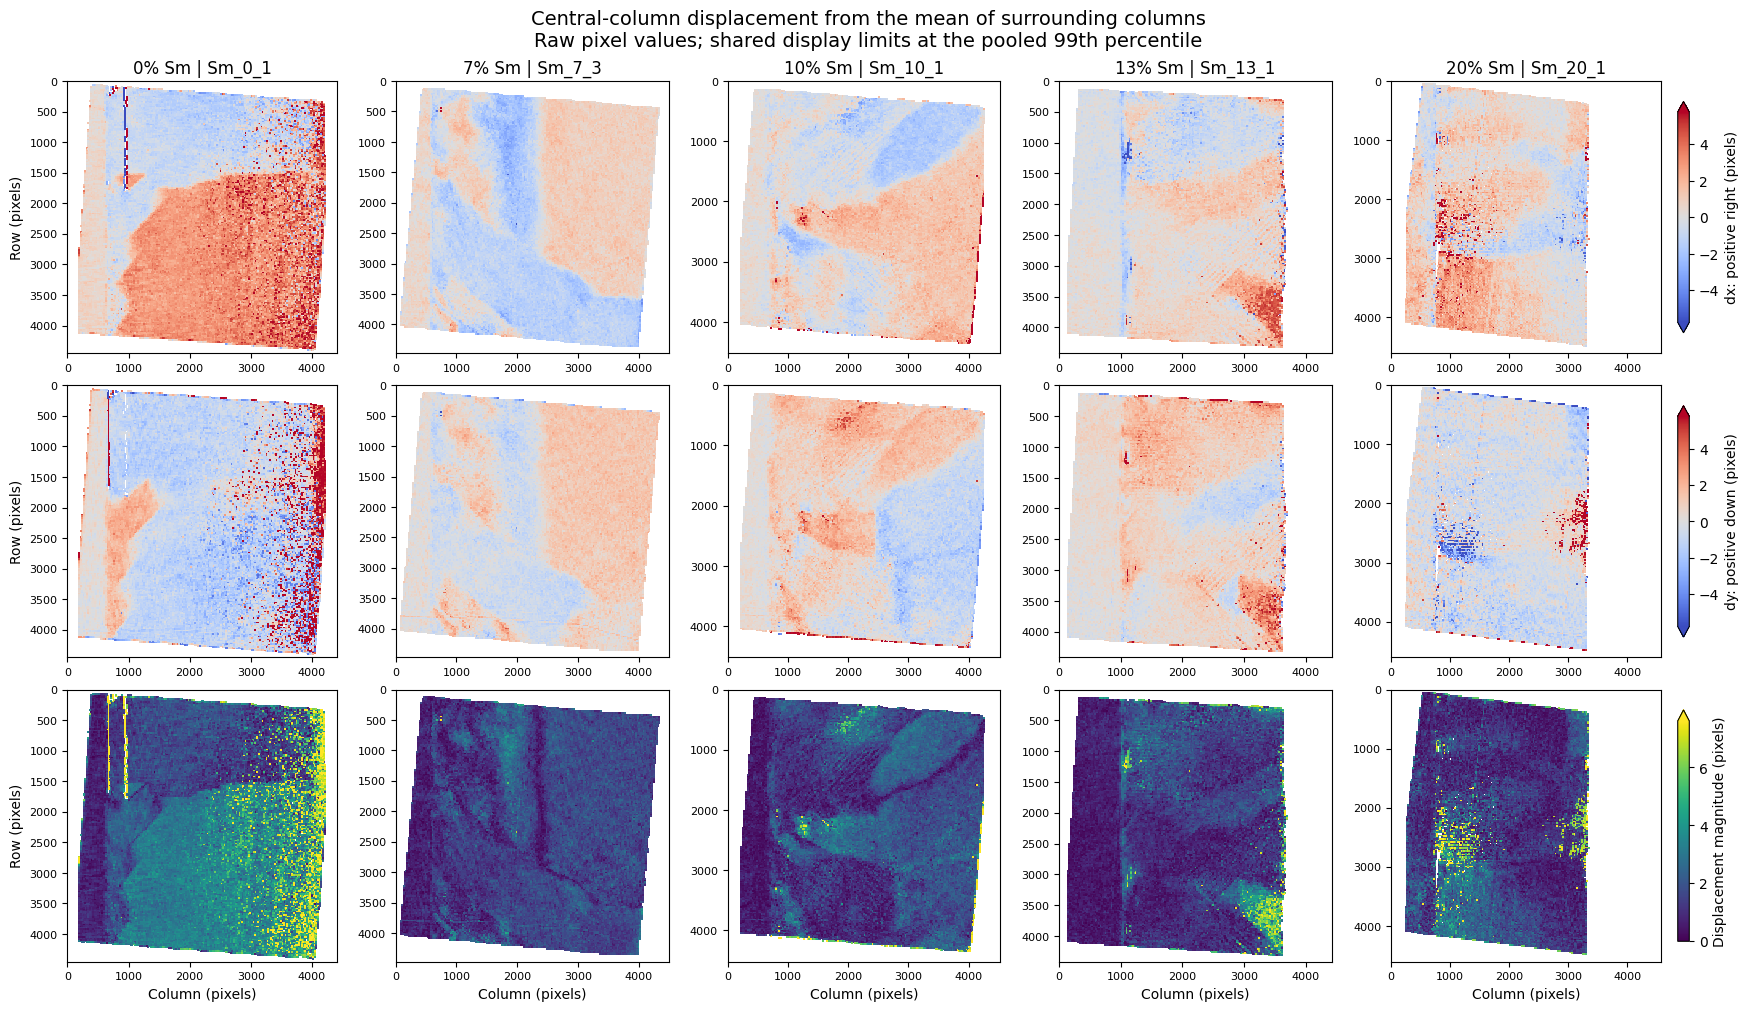

Map figure: /content/hackathon_outputs/block02_baseline_20261106T213244_508770Z_maps.png

Block 2 complete. Results are in ha_baseline.
Color saturation changes display only; saved displacement values are not clipped.
This block did not read Pxy. The reference sign, axes, and units remain unverified.


In [ ]:
# BLOCK 2 — Reconstruct and save the geometric displacement baseline.
# Requires Block 1. Uses no reference polarization values.

from pathlib import Path
from datetime import datetime, timezone
import hashlib
import json
import numpy as np
import matplotlib.pyplot as plt

if "hackathon_samples" not in globals() or not hackathon_samples:
    raise RuntimeError("Run Block 1 successfully before running Block 2.")


def ha_offset_rc(atoms_rc):
    """Central atom 5 minus the mean of surrounding atoms 1–4."""
    a = np.asarray(atoms_rc, dtype=float)

    if a.ndim != 3 or a.shape[1:] != (5, 2):
        raise ValueError(
            f"Expected (cells, 5, 2), received {a.shape}"
        )

    return a[:, 4, :] - a[:, :4, :].mean(axis=1)


# ------------------------------------------------------------
# 1. Check the calculation using simple synthetic coordinates.
# ------------------------------------------------------------

ha_toy = np.array([
    [[0., 0.], [2., 0.], [2., 2.], [0., 2.], [1., 1.]]
])

# A centered atom should have zero displacement.
np.testing.assert_allclose(
    ha_offset_rc(ha_toy),
    [[0., 0.]],
    atol=1e-12,
)

# Move only the central atom: +0.25 row, -0.50 column.
ha_toy_shifted = ha_toy.copy()
ha_toy_shifted[:, 4, :] += [0.25, -0.50]

np.testing.assert_allclose(
    ha_offset_rc(ha_toy_shifted),
    [[0.25, -0.50]],
    atol=1e-12,
)

# Moving the whole cell should not change its displacement.
np.testing.assert_allclose(
    ha_offset_rc(ha_toy_shifted + [100., 200.]),
    ha_offset_rc(ha_toy_shifted),
    atol=1e-12,
)

print(
    "Implementation checks passed: zero offset, known shift, "
    "and translation invariance."
)


# ------------------------------------------------------------
# 2. Record the method and coordinate conventions.
# ------------------------------------------------------------

ha_created = datetime.now(timezone.utc)

ha_baseline_config = {
    "method": "central_atom_minus_mean_of_four_surrounding_atoms",
    "formula": (
        "d_rc = atoms_rc[:, 4, :] "
        "- atoms_rc[:, :4, :].mean(axis=1)"
    ),
    "created_utc": ha_created.isoformat(),
    "cell_ids": "original zero-based row indices",
    "coordinate_order": ["row", "column"],
    "units": "pixels; physical pixel calibration unavailable",
    "dx": "positive right; column component",
    "dy": "positive down; row component",
    "angle_deg": (
        "atan2(dy, dx); clockwise from right; "
        "zero-vector angle is NaN"
    ),
    "map_positions": (
        "supplied xy_COM; corner centroid saved separately"
    ),
    "valid": (
        "all five atomic positions finite and inside "
        "image bounds, from Block 1"
    ),
    "reference_values_used": False,
    "target_Pxy_convention": (
        "unresolved; these are raw geometric displacements"
    ),
    "smoothing": False,
    "mean_subtraction": False,
    "display_percentile": 99.0,
    "samples": [],
}


# ------------------------------------------------------------
# 3. Calculate the displacement for every valid unit cell.
# ------------------------------------------------------------

ha_baseline = {}

print("\nGEOMETRIC DISPLACEMENTS — all values below are in pixels")

print(
    f"{'Sample':<12} {'Valid/total':>15} "
    f"{'Mean dx':>10} {'Mean dy':>10} "
    f"{'Median |d|':>12} {'P95 |d|':>10} {'Max |d|':>10}"
)

for ha_s in sorted(
    hackathon_samples,
    key=lambda s: (s["sm_percent"], s["sample_id"]),
):
    ha_id = ha_s["sample_id"]
    ha_a = np.asarray(ha_s["atoms_rc"], dtype=float)
    ha_ok = np.asarray(
        ha_s["coordinate_valid"], dtype=bool
    ).copy()

    ha_n = len(ha_a)

    # Preserve every original cell row.
    # Invalid cells retain NaN predictions.
    ha_drc = np.full((ha_n, 2), np.nan)
    ha_cage = np.full((ha_n, 2), np.nan)

    ha_drc[ha_ok] = ha_offset_rc(ha_a[ha_ok])
    ha_cage[ha_ok] = ha_a[ha_ok, :4, :].mean(axis=1)

    # Stored coordinates are row, column.
    # Horizontal displacement therefore comes from column.
    ha_dx = ha_drc[:, 1].copy()
    ha_dy = ha_drc[:, 0].copy()

    ha_mag = np.hypot(ha_dx, ha_dy)

    # Image-coordinate angle:
    # 0° = right, +90° = down, -90° = up.
    ha_angle = np.full(ha_n, np.nan)
    ha_nonzero = ha_ok & (ha_mag > 0)

    ha_angle[ha_nonzero] = np.degrees(
        np.arctan2(
            ha_dy[ha_nonzero],
            ha_dx[ha_nonzero],
        )
    )

    ha_r = {
        "cell_id": np.array(ha_s["cell_ids"], copy=True),
        "sm_percent": np.asarray(ha_s["sm_percent"]),
        "image_shape": np.asarray(ha_s["image_shape"]),
        "map_rc": np.array(ha_s["com_rc"], copy=True),
        "corner_center_rc": ha_cage,
        "dx_px": ha_dx,
        "dy_px": ha_dy,
        "magnitude_px": ha_mag,
        "angle_deg_image": ha_angle,
        "valid": ha_ok,
        "map_valid": (
            ha_ok
            & np.asarray(ha_s["com_valid"], dtype=bool)
        ),
    }

    ha_baseline[ha_id] = ha_r

    ha_baseline_config["samples"].append({
        "sample_id": ha_id,
        "sm_percent": int(ha_s["sm_percent"]),
        "image_file": Path(ha_s["image_path"]).name,
        "parameter_file": Path(ha_s["parameter_path"]).name,
        "cells": ha_n,
    })

    if ha_ok.any():
        print(
            f"{ha_id:<12} "
            f"{str(int(ha_ok.sum())) + '/' + str(ha_n):>15} "
            f"{ha_dx[ha_ok].mean():10.4f} "
            f"{ha_dy[ha_ok].mean():10.4f} "
            f"{np.median(ha_mag[ha_ok]):12.4f} "
            f"{np.percentile(ha_mag[ha_ok], 95):10.4f} "
            f"{ha_mag[ha_ok].max():10.4f}"
        )
    else:
        print(f"{ha_id:<12} No valid predictions.")


# ------------------------------------------------------------
# 4. Check how xy_COM relates to the four-corner center.
#    This is diagnostic only; it does not change predictions.
# ------------------------------------------------------------

print(
    "\nLOCATION CHECK — distance between xy_COM "
    "and the four-corner center (pixels)"
)

for ha_id, ha_r in ha_baseline.items():
    ha_ok = ha_r["map_valid"]

    if ha_ok.any():
        ha_gap = np.linalg.norm(
            ha_r["map_rc"][ha_ok]
            - ha_r["corner_center_rc"][ha_ok],
            axis=1,
        )

        print(
            f"{ha_id}: "
            f"median = {np.median(ha_gap):.6f}, "
            f"P95 = {np.percentile(ha_gap, 95):.6f}; "
            f"mapped cells = {ha_ok.sum():,}/{len(ha_ok):,}"
        )


# ------------------------------------------------------------
# 5. Save the numerical predictions before reference evaluation.
# ------------------------------------------------------------

ha_output_dir = Path("hackathon_outputs")
ha_output_dir.mkdir(parents=True, exist_ok=True)

ha_stem = (
    "block02_baseline_"
    + ha_created.strftime("%Y%m%dT%H%M%S_%fZ")
)

ha_archive = {
    "config_json": np.asarray(
        json.dumps(ha_baseline_config, indent=2)
    )
}

for ha_id, ha_r in ha_baseline.items():
    for ha_key, ha_value in ha_r.items():
        ha_archive[f"{ha_id}__{ha_key}"] = ha_value

ha_snapshot_path = ha_output_dir / f"{ha_stem}.npz"
np.savez_compressed(ha_snapshot_path, **ha_archive)

print("\nPrediction snapshot:", ha_snapshot_path.resolve())
print(
    "SHA-256:",
    hashlib.sha256(ha_snapshot_path.read_bytes()).hexdigest(),
)


# ------------------------------------------------------------
# 6. Set common color limits for display only.
#    No saved prediction values are clipped or modified.
# ------------------------------------------------------------

ha_plot_records = [
    r for r in ha_baseline.values()
    if r["map_valid"].any()
]

if not ha_plot_records:
    raise RuntimeError(
        "Snapshot saved, but there are no valid map locations to plot."
    )

ha_component_pool = np.concatenate([
    np.abs(r[k][r["map_valid"]])
    for r in ha_plot_records
    for k in ["dx_px", "dy_px"]
])

ha_magnitude_pool = np.concatenate([
    r["magnitude_px"][r["map_valid"]]
    for r in ha_plot_records
])

ha_component_limit = (
    float(np.percentile(ha_component_pool, 99)) or 1.0
)

ha_magnitude_limit = (
    float(np.percentile(ha_magnitude_pool, 99)) or 1.0
)

ha_rows = [
    (
        "dx_px",
        "dx: positive right (pixels)",
        "coolwarm",
        -ha_component_limit,
        ha_component_limit,
    ),
    (
        "dy_px",
        "dy: positive down (pixels)",
        "coolwarm",
        -ha_component_limit,
        ha_component_limit,
    ),
    (
        "magnitude_px",
        "Displacement magnitude (pixels)",
        "viridis",
        0.,
        ha_magnitude_limit,
    ),
]


# ------------------------------------------------------------
# 7. Plot dx, dy, and magnitude for all compositions.
# ------------------------------------------------------------

ha_map_fig, ha_map_axes = plt.subplots(
    3,
    len(ha_baseline),
    figsize=(3.5 * len(ha_baseline), 10),
    squeeze=False,
    layout="constrained",
)

for ha_row, (
    ha_key, ha_label, ha_cmap, ha_vmin, ha_vmax
) in enumerate(ha_rows):

    for ha_col, (ha_id, ha_r) in enumerate(
        ha_baseline.items()
    ):
        ha_ax = ha_map_axes[ha_row, ha_col]
        ha_ok = ha_r["map_valid"]
        ha_points = ha_r["map_rc"][ha_ok]

        ha_artist = ha_ax.scatter(
            ha_points[:, 1],
            ha_points[:, 0],
            c=ha_r[ha_key][ha_ok],
            cmap=ha_cmap,
            vmin=ha_vmin,
            vmax=ha_vmax,
            s=2,
            marker="s",
            linewidths=0,
            rasterized=True,
        )

        ha_h, ha_w = ha_r["image_shape"]

        ha_ax.set(
            xlim=(0, ha_w - 1),
            ylim=(ha_h - 1, 0),
            aspect="equal",
        )

        ha_ax.tick_params(labelsize=8)

        if ha_row == 0:
            ha_ax.set_title(
                f"{int(ha_r['sm_percent'])}% Sm | {ha_id}"
            )

        if ha_col == 0:
            ha_ax.set_ylabel("Row (pixels)")

        if ha_row == 2:
            ha_ax.set_xlabel("Column (pixels)")

    ha_cb = ha_map_fig.colorbar(
        ha_artist,
        ax=ha_map_axes[ha_row, :].tolist(),
        shrink=0.85,
        pad=0.01,
        extend="both" if ha_row < 2 else "max",
    )

    ha_cb.set_label(ha_label)

ha_map_fig.suptitle(
    "Central-column displacement from the mean of surrounding columns\n"
    "Raw pixel values; shared display limits at the pooled 99th percentile",
    fontsize=14,
)

ha_map_path = ha_output_dir / f"{ha_stem}_maps.png"
ha_map_fig.savefig(ha_map_path, dpi=180)

plt.show()

print("Map figure:", ha_map_path.resolve())
print("\nBlock 2 complete. Results are in ha_baseline.")
print(
    "Color saturation changes display only; "
    "saved displacement values are not clipped."
)
print(
    "This block did not read Pxy. "
    "The reference sign, axes, and units remain unverified."
)

GEOMETRY CHECK — flags are diagnostic; baseline predictions are unchanged.
Edge scale = median length of the four cage edges, in image pixels.
COM identity check compares coordinate vectors; no scale is fitted.

Sm_0_1
  xy_COM minus mean(all 5): median error = 0.000e+00 px; maximum = 0.000e+00 px
  Convex cages: 23,541/23,541; atom 5 inside/on cage: 23,535/23,541
  Median cage-edge scale: 26.178 px
  |d| / edge: median = 0.1039; P95 = 0.2623; maximum = 0.6951
  Preview cell IDs: [16025, 9135] 

Sm_7_3
  xy_COM minus mean(all 5): median error = 0.000e+00 px; maximum = 0.000e+00 px
  Convex cages: 23,074/23,074; atom 5 inside/on cage: 23,074/23,074
  Median cage-edge scale: 26.097 px
  |d| / edge: median = 0.0565; P95 = 0.0944; maximum = 0.3382
  Preview cell IDs: [7578, 22213] 

Sm_10_1
  xy_COM minus mean(all 5): median error = 0.000e+00 px; maximum = 0.000e+00 px
  Convex cages: 22,949/22,949; atom 5 inside/on cage: 22,949/22,949
  Median cage-edge scale: 26.015 px
  |d| / edge: medi

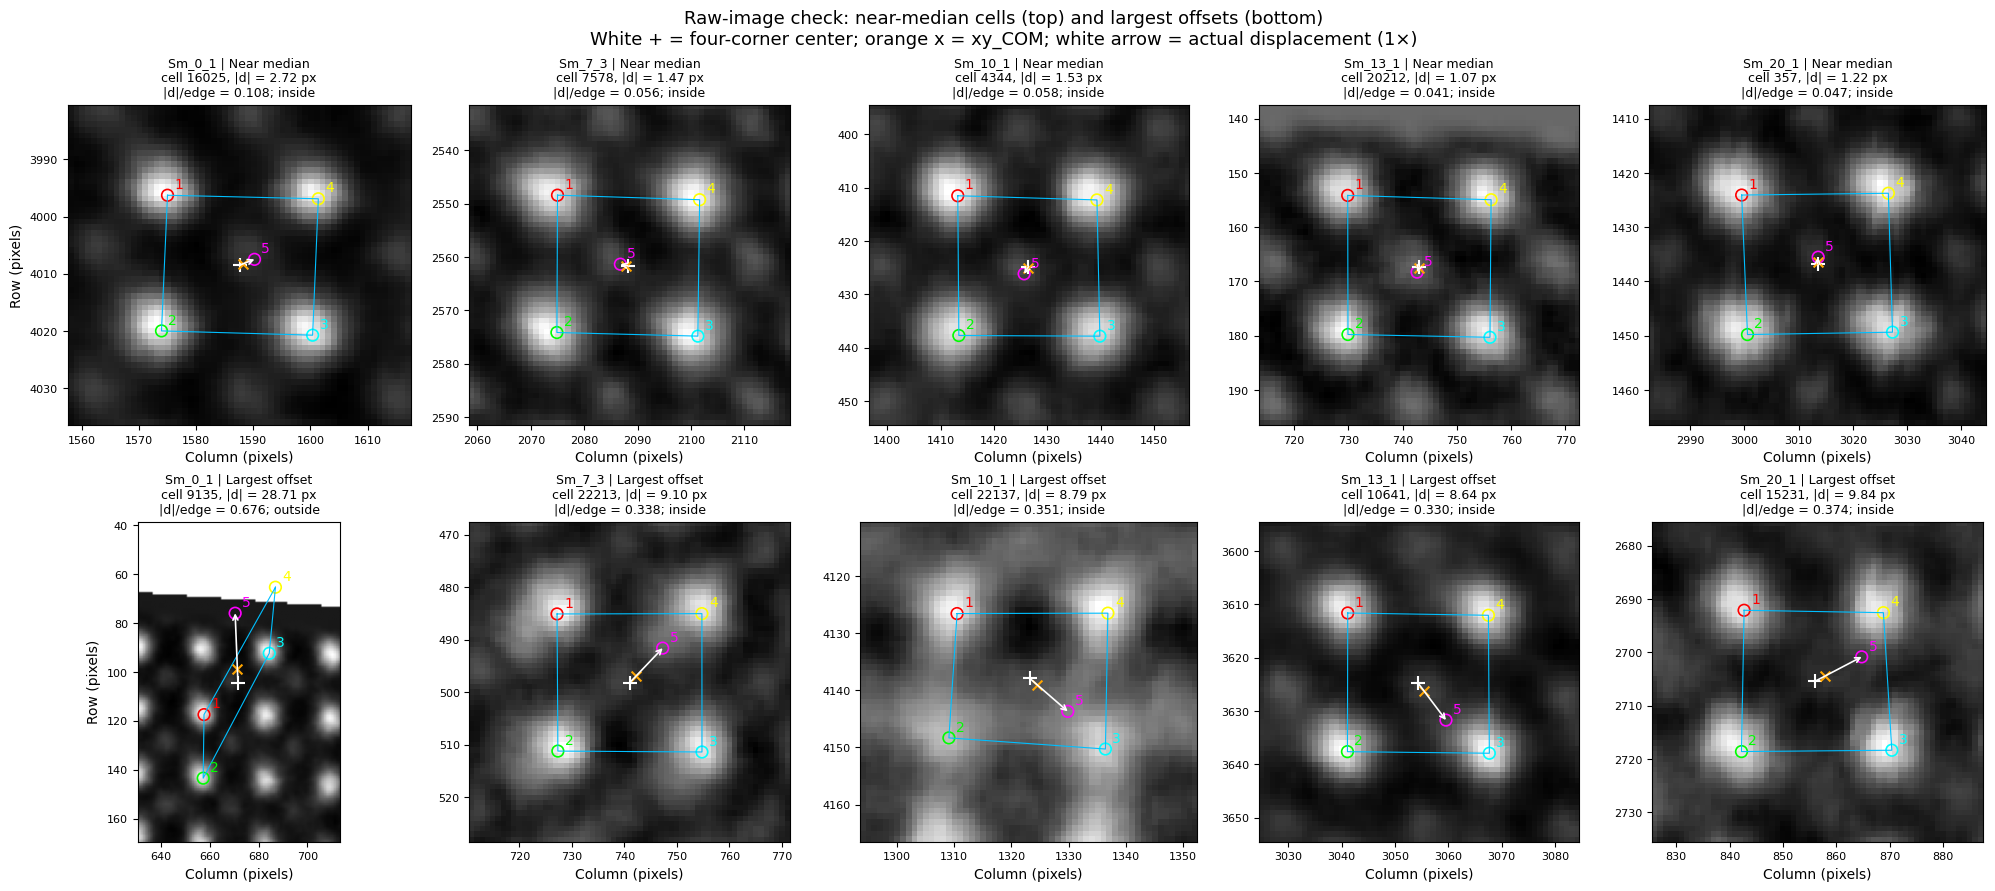

Saved image check: /content/hackathon_outputs/block03_geometry_20261106T213251_683338Z.png
Saved geometry diagnostics: /content/hackathon_outputs/block03_geometry_20261106T213251_683338Z.npz
Block 3 complete. No cells were removed and no baseline values were changed.


In [ ]:
# BLOCK 3 — Verify the coordinate reference and inspect typical/extreme cells.
# Diagnostic only: no Pxy access, filtering, or changes to ha_baseline.

from pathlib import Path
from datetime import datetime, timezone
import json
import h5py
import numpy as np
import matplotlib.pyplot as plt

if "hackathon_samples" not in globals() or "ha_baseline" not in globals():
    raise RuntimeError("Run Blocks 1 and 2 before this block.")


def ha_cross2(a, b):
    """Two-dimensional cross product."""
    return a[..., 0] * b[..., 1] - a[..., 1] * b[..., 0]


def ha_geometry_check(sample, baseline):
    a = np.asarray(sample["atoms_rc"], dtype=float)
    valid = np.asarray(baseline["valid"], dtype=bool)

    np.testing.assert_array_equal(
        sample["cell_ids"], baseline["cell_id"]
    )

    if len(a) != len(valid) or not valid.any():
        raise ValueError(
            f"{sample['sample_id']}: no matching valid cells."
        )

    ids = np.flatnonzero(valid)
    corners = a[valid, :4, :]
    center = corners.mean(axis=1)

    # Order the surrounding points around their geometric center.
    # This avoids assuming that atom labels are already cyclically ordered.
    angles = np.arctan2(
        corners[:, :, 0] - center[:, None, 0],
        corners[:, :, 1] - center[:, None, 1],
    )

    order = np.argsort(angles, axis=1)
    quad = np.take_along_axis(
        corners, order[:, :, None], axis=1
    )

    edges = np.roll(quad, -1, axis=1) - quad
    edge_scale = np.median(
        np.linalg.norm(edges, axis=2), axis=1
    )

    # Numerical tolerance for cross products, in pixels squared.
    tolerance = 1e-10 * np.maximum(edge_scale**2, 1.)

    turns = ha_cross2(
        edges, np.roll(edges, -1, axis=1)
    )

    convex = (
        (turns > tolerance[:, None]).all(axis=1)
        | (turns < -tolerance[:, None]).all(axis=1)
    )

    # Test whether atom 5 lies inside or on the convex quadrilateral.
    sides = ha_cross2(
        edges, a[valid, 4, None, :] - quad
    )

    inside = convex & (
        (sides >= -tolerance[:, None]).all(axis=1)
        | (sides <= tolerance[:, None]).all(axis=1)
    )

    # Preserve every original cell row.
    result = {
        "cell_id": np.array(baseline["cell_id"], copy=True),
        "valid": valid.copy(),
        "convex": np.zeros(len(a), dtype=bool),
        "inside": np.zeros(len(a), dtype=bool),
        "edge_px": np.full(len(a), np.nan),
        "relative_displacement": np.full(len(a), np.nan),
        "com_minus_mean5_rc": np.full((len(a), 2), np.nan),
        "ordered_corners_rc": np.full((len(a), 4, 2), np.nan),
    }

    result["convex"][ids] = convex
    result["inside"][ids] = inside
    result["edge_px"][ids] = edge_scale
    result["ordered_corners_rc"][ids] = quad

    # Dimensionless geometry diagnostic.
    # This is not a calibrated crystallographic lattice constant.
    ratio_ids = ids[convex & (edge_scale > 0)]

    result["relative_displacement"][ratio_ids] = (
        baseline["magnitude_px"][ratio_ids]
        / result["edge_px"][ratio_ids]
    )

    # Directly test whether xy_COM equals the mean of all five positions.
    com_ok = valid & np.asarray(
        sample["com_valid"], dtype=bool
    )

    result["com_minus_mean5_rc"][com_ok] = (
        sample["com_rc"][com_ok]
        - a[com_ok].mean(axis=1)
    )

    return result


ha_geometry_audit = {}

ha_b3_samples = sorted(
    hackathon_samples,
    key=lambda s: (s["sm_percent"], s["sample_id"]),
)

ha_b3_fig, ha_b3_axes = plt.subplots(
    2,
    len(ha_b3_samples),
    figsize=(4 * len(ha_b3_samples), 8.8),
    squeeze=False,
    layout="constrained",
)

print(
    "GEOMETRY CHECK — flags are diagnostic; "
    "baseline predictions are unchanged."
)
print(
    "Edge scale = median length of the four cage edges, "
    "in image pixels."
)
print(
    "COM identity check compares coordinate vectors; "
    "no scale is fitted.\n"
)

for ha_col, ha_s in enumerate(ha_b3_samples):
    ha_id = ha_s["sample_id"]
    ha_r = ha_baseline[ha_id]
    ha_g = ha_geometry_check(ha_s, ha_r)

    ha_geometry_audit[ha_id] = ha_g
    ha_ids = np.flatnonzero(ha_g["valid"])

    ha_com_error = np.linalg.norm(
        ha_g["com_minus_mean5_rc"], axis=1
    )
    ha_finite_com = np.isfinite(ha_com_error)

    ha_ratios = ha_g["relative_displacement"]
    ha_ratio_ok = np.isfinite(ha_ratios)

    print(ha_id)

    if ha_finite_com.any():
        print(
            "  xy_COM minus mean(all 5): "
            f"median error = "
            f"{np.median(ha_com_error[ha_finite_com]):.3e} px; "
            f"maximum = "
            f"{ha_com_error[ha_finite_com].max():.3e} px"
        )

    print(
        f"  Convex cages: "
        f"{ha_g['convex'].sum():,}/{len(ha_ids):,}; "
        f"atom 5 inside/on cage: "
        f"{ha_g['inside'].sum():,}/{ha_g['convex'].sum():,}"
    )

    if ha_ratio_ok.any():
        print(
            "  Median cage-edge scale: "
            f"{np.median(ha_g['edge_px'][ha_ratio_ok]):.3f} px"
        )
        print(
            "  |d| / edge: "
            f"median = {np.median(ha_ratios[ha_ratio_ok]):.4f}; "
            f"P95 = "
            f"{np.percentile(ha_ratios[ha_ratio_ok], 95):.4f}; "
            f"maximum = {ha_ratios[ha_ratio_ok].max():.4f}"
        )

    # Select examples using our reconstruction only.
    ha_mags = ha_r["magnitude_px"][ha_ids]

    ha_choices = [
        (
            "Near median",
            ha_ids[
                np.argmin(
                    np.abs(ha_mags - np.median(ha_mags))
                )
            ],
        ),
        (
            "Largest offset",
            ha_ids[np.argmax(ha_mags)],
        ),
    ]

    ha_g["preview_cell_id"] = np.array([
        ha_r["cell_id"][i] for _, i in ha_choices
    ])

    # Read only the raw HAADF image.
    with h5py.File(ha_s["image_path"], "r") as ha_f:
        ha_image = np.asarray(
            ha_f["MainImage"]
        ).squeeze()

    if tuple(ha_image.shape) != tuple(ha_s["image_shape"]):
        raise ValueError(
            f"{ha_id}: image dimensions changed since Block 1."
        )

    ha_h, ha_w = ha_image.shape

    for ha_row, (ha_tag, ha_i) in enumerate(ha_choices):
        ha_ax = ha_b3_axes[ha_row, ha_col]
        ha_pts = ha_s["atoms_rc"][ha_i]
        ha_quad = ha_g["ordered_corners_rc"][ha_i]
        ha_center = ha_pts[:4].mean(axis=0)

        ha_margin = max(
            8., 0.6 * ha_g["edge_px"][ha_i]
        )

        ha_r0 = max(
            0,
            int(np.floor(ha_pts[:, 0].min() - ha_margin)),
        )
        ha_r1 = min(
            ha_h,
            int(np.ceil(ha_pts[:, 0].max() + ha_margin)) + 1,
        )
        ha_c0 = max(
            0,
            int(np.floor(ha_pts[:, 1].min() - ha_margin)),
        )
        ha_c1 = min(
            ha_w,
            int(np.ceil(ha_pts[:, 1].max() + ha_margin)) + 1,
        )

        ha_ax.imshow(
            ha_image[ha_r0:ha_r1, ha_c0:ha_c1].copy(),
            cmap="gray",
            origin="upper",
            extent=(
                ha_c0 - .5,
                ha_c1 - .5,
                ha_r1 - .5,
                ha_r0 - .5,
            ),
        )

        # Outline the four-corner cell.
        ha_closed = np.vstack([ha_quad, ha_quad[0]])
        ha_ax.plot(
            ha_closed[:, 1],
            ha_closed[:, 0],
            color="deepskyblue",
            lw=.8,
        )

        # Number the supplied atomic positions.
        for ha_k, (ha_y, ha_x) in enumerate(ha_pts):
            ha_color = [
                "red", "lime", "cyan", "yellow", "magenta"
            ][ha_k]

            ha_ax.scatter(
                ha_x,
                ha_y,
                s=70,
                facecolors="none",
                edgecolors=ha_color,
                lw=1.2,
            )

            ha_ax.annotate(
                str(ha_k + 1),
                (ha_x, ha_y),
                xytext=(5, 5),
                textcoords="offset points",
                color=ha_color,
                fontsize=10,
            )

        # Four-corner center.
        ha_ax.scatter(
            ha_center[1],
            ha_center[0],
            marker="+",
            s=100,
            c="white",
            lw=1.5,
        )

        # Actual displacement: no arrow magnification.
        ha_ax.annotate(
            "",
            xy=(ha_pts[4, 1], ha_pts[4, 0]),
            xytext=(ha_center[1], ha_center[0]),
            arrowprops=dict(
                arrowstyle="->",
                color="white",
                lw=1.2,
                shrinkA=0,
                shrinkB=0,
                mutation_scale=9,
            ),
        )

        # Supplied unit-cell reference.
        if ha_s["com_valid"][ha_i]:
            ha_com = ha_s["com_rc"][ha_i]
            ha_ax.scatter(
                ha_com[1],
                ha_com[0],
                marker="x",
                s=50,
                c="orange",
            )

        if not ha_g["convex"][ha_i]:
            ha_status = "invalid cage"
        elif ha_g["inside"][ha_i]:
            ha_status = "inside"
        else:
            ha_status = "outside"

        ha_ax.set_title(
            f"{ha_id} | {ha_tag}\n"
            f"cell {ha_r['cell_id'][ha_i]}, "
            f"|d| = {ha_r['magnitude_px'][ha_i]:.2f} px\n"
            f"|d|/edge = {ha_ratios[ha_i]:.3f}; "
            f"{ha_status}",
            fontsize=9,
        )

        ha_ax.set(
            xlim=(ha_c0 - .5, ha_c1 - .5),
            ylim=(ha_r1 - .5, ha_r0 - .5),
            aspect="equal",
        )

        ha_ax.tick_params(labelsize=8)
        ha_ax.set_xlabel("Column (pixels)")

        if ha_col == 0:
            ha_ax.set_ylabel("Row (pixels)")

    print(
        "  Preview cell IDs:",
        ha_g["preview_cell_id"].tolist(),
        "\n",
    )

    del ha_image


ha_b3_fig.suptitle(
    "Raw-image check: near-median cells (top) "
    "and largest offsets (bottom)\n"
    "White + = four-corner center; orange x = xy_COM; "
    "white arrow = actual displacement (1×)",
    fontsize=13,
)

ha_b3_dir = Path("hackathon_outputs")
ha_b3_dir.mkdir(parents=True, exist_ok=True)

ha_b3_stem = (
    "block03_geometry_"
    + datetime.now(timezone.utc).strftime(
        "%Y%m%dT%H%M%S_%fZ"
    )
)

ha_b3_png = ha_b3_dir / f"{ha_b3_stem}.png"
ha_b3_fig.savefig(ha_b3_png, dpi=180)

plt.show()


# Save diagnostic arrays separately from the baseline predictions.
ha_b3_archive = {
    "config_json": np.asarray(json.dumps({
        "purpose": (
            "diagnostic only; no baseline filtering "
            "or modification"
        ),
        "reference_values_used": False,
        "baseline_snapshot": str(
            globals().get("ha_snapshot_path", "unspecified")
        ),
        "edge_scale": (
            "median of four angularly ordered "
            "polygon edge lengths, pixels"
        ),
        "cross_product_tolerance": (
            "1e-10 * max(edge_scale**2, 1), pixels squared"
        ),
        "com_residual": (
            "xy_COM - arithmetic mean of "
            "all five atomic positions"
        ),
        "preview_selection": (
            "closest to median magnitude and maximum "
            "magnitude among valid cells"
        ),
    }))
}

for ha_id, ha_g in ha_geometry_audit.items():
    for ha_key, ha_value in ha_g.items():
        if ha_key != "ordered_corners_rc":
            ha_b3_archive[f"{ha_id}__{ha_key}"] = ha_value

ha_b3_npz = ha_b3_dir / f"{ha_b3_stem}.npz"
np.savez_compressed(ha_b3_npz, **ha_b3_archive)

print("Saved image check:", ha_b3_png.resolve())
print("Saved geometry diagnostics:", ha_b3_npz.resolve())
print(
    "Block 3 complete. No cells were removed "
    "and no baseline values were changed."
)

In [ ]:
# BLOCK 4A — Define the image-only localization model.

import numpy as np
from scipy.optimize import least_squares


def _ha_gaussian_plane(params, rr, cc):
    """Gaussian plus planar background and its analytic Jacobian."""
    amp, dr, dc, sr, sc, b0, br, bc = params

    u, v = rr - dr, cc - dc
    gaussian = np.exp(
        -0.5 * ((u / sr)**2 + (v / sc)**2)
    )
    peak = amp * gaussian

    radius_scale = max(
        float(np.max(np.abs(rr))),
        float(np.max(np.abs(cc))),
        1.0,
    )
    row_plane = rr / radius_scale
    col_plane = cc / radius_scale

    model = peak + b0 + br * row_plane + bc * col_plane

    jacobian = np.column_stack((
        gaussian.ravel(),
        (peak * u / sr**2).ravel(),
        (peak * v / sc**2).ravel(),
        (peak * u**2 / sr**3).ravel(),
        (peak * v**2 / sc**3).ravel(),
        np.ones(rr.size),
        row_plane.ravel(),
        col_plane.ravel(),
    ))

    return model, jacobian


def ha_fit_gaussian_peak(
    image,
    seed_rc,
    patch_radius=6,
    *,
    max_axis_shift_px=2.0,
    max_shift_px=2.0,
    min_peak_to_residual=5.0,
    bound_margin_px=0.02,
    max_nfev=60,
    return_arrays=False,
):
    """
    Refine one supplied atomic position using image pixels only.

    The peak center starts at the supplied floating-point position.
    Accepted movement is limited to 2 pixels by default.

    Acceptance thresholds are heuristic fit-quality checks.
    They are not calibrated uncertainty or accuracy estimates.

    Rejected fits return NaN refined coordinates.
    """
    result = {
        "success": False,
        "reason": "unattempted",
        "refined_rc": np.full(2, np.nan),
        "shift_rc": np.full(2, np.nan),
        "shift_px": np.nan,
        "residual_rms_normalized": np.nan,
        "peak_to_residual_ratio": np.nan,
        "nfev": 0,
        "optimizer_success": False,
        "fit_params": np.full(8, np.nan),
    }

    def reject(reason):
        result["reason"] = reason
        return result

    im = np.asarray(image)
    seed = np.asarray(seed_rc, dtype=float)

    if (
        im.ndim != 2
        or seed.shape != (2,)
        or not np.all(np.isfinite(seed))
    ):
        return reject("invalid_image_or_seed")

    if (
        not np.isscalar(patch_radius)
        or not np.isfinite(patch_radius)
        or int(patch_radius) != patch_radius
        or patch_radius < 3
    ):
        raise ValueError("patch_radius must be an integer >= 3")

    radius = int(patch_radius)

    if not (
        max_axis_shift_px > bound_margin_px >= 0
        and max_shift_px > 0
        and min_peak_to_residual > 0
        and max_nfev >= 1
    ):
        raise ValueError("Invalid fit bounds or acceptance thresholds")

    if not (
        0 <= seed[0] <= im.shape[0] - 1
        and 0 <= seed[1] <= im.shape[1] - 1
    ):
        return reject("seed_outside_image")

    # Crop around the nearest pixel, but retain the fractional seed
    # when defining the model coordinates.
    anchor = np.floor(seed + 0.5).astype(int)
    r0 = int(anchor[0] - radius)
    r1 = int(anchor[0] + radius + 1)
    c0 = int(anchor[1] - radius)
    c1 = int(anchor[1] + radius + 1)

    if (
        r0 < 0 or c0 < 0
        or r1 > im.shape[0] or c1 > im.shape[1]
    ):
        return reject("incomplete_patch")

    patch = np.asarray(im[r0:r1, c0:c1], dtype=float)

    if not np.all(np.isfinite(patch)):
        return reject("nonfinite_patch")

    q05, q95 = np.percentile(patch, [5.0, 95.0])

    tiny = (
        32 * np.finfo(float).eps
        * max(float(np.max(np.abs(patch))), 1.0)
    )

    scale = float(q95 - q05)
    normalization = "p05_p95"

    if scale <= tiny:
        scale = float(np.ptp(patch))
        normalization = "range_fallback"

    if scale <= tiny or not np.isfinite(scale):
        return reject("flat_patch")

    # Normalize for fitting; do not clip any pixels.
    data = (patch - q05) / scale

    rr, cc = np.meshgrid(
        np.arange(r0, r1, dtype=float) - seed[0],
        np.arange(c0, c1, dtype=float) - seed[1],
        indexing="ij",
    )

    border = np.concatenate((
        data[0],
        data[-1],
        data[1:-1, 0],
        data[1:-1, -1],
    ))

    background0 = float(np.median(border))
    amplitude0 = max(float(np.max(data) - background0), 1e-3)

    width_lo = 0.6
    width_hi = 0.8 * radius

    if width_hi - width_lo <= 2 * bound_margin_px:
        raise ValueError("Width interval is too small")

    width0 = float(
        np.clip(radius / 2, width_lo + 0.1, width_hi - 0.1)
    )

    initial = np.array([
        amplitude0, 0, 0,
        width0, width0,
        background0, 0, 0,
    ])

    lower = np.array([
        0,
        -max_axis_shift_px,
        -max_axis_shift_px,
        width_lo,
        width_lo,
        -np.inf,
        -np.inf,
        -np.inf,
    ])

    upper = np.array([
        np.inf,
        max_axis_shift_px,
        max_axis_shift_px,
        width_hi,
        width_hi,
        np.inf,
        np.inf,
        np.inf,
    ])

    def residual(params):
        return (
            _ha_gaussian_plane(params, rr, cc)[0] - data
        ).ravel()

    def jacobian(params):
        return _ha_gaussian_plane(params, rr, cc)[1]

    try:
        fit = least_squares(
            residual,
            initial,
            jac=jacobian,
            bounds=(lower, upper),
            method="trf",
            loss="soft_l1",
            f_scale=0.1,
            max_nfev=int(max_nfev),
            x_scale="jac",
        )
    except (
        ValueError,
        FloatingPointError,
        np.linalg.LinAlgError,
    ) as exc:
        result["exception_type"] = type(exc).__name__
        return reject("optimizer_exception")

    model, _ = _ha_gaussian_plane(fit.x, rr, cc)

    # Report the unweighted RMS across all pixels.
    rms = float(np.sqrt(np.mean((model - data)**2)))
    ratio = float(
        fit.x[0] / max(rms, np.finfo(float).eps)
    )
    shift_norm = float(np.linalg.norm(fit.x[1:3]))

    result.update(
        shift_px=shift_norm,
        residual_rms_normalized=rms,
        peak_to_residual_ratio=ratio,
        nfev=int(fit.nfev),
        optimizer_success=bool(fit.success),
        fit_params=fit.x.copy(),
        normalization=normalization,
        normalization_offset=float(q05),
        normalization_scale=scale,
        patch_bounds_rc=(r0, r1, c0, c1),
    )

    if return_arrays:
        result.update(
            patch=patch.copy(),
            model=model * scale + q05,
            residual_normalized=model - data,
        )

    reasons = []

    if not fit.success:
        reasons.append("optimizer_not_converged")

    if not (
        np.all(np.isfinite(fit.x))
        and np.isfinite(rms)
        and np.isfinite(ratio)
    ):
        reasons.append("nonfinite_fit")

    if np.any(
        max_axis_shift_px - np.abs(fit.x[1:3])
        <= bound_margin_px
    ):
        reasons.append("center_at_bound")

    if np.any(
        np.minimum(
            fit.x[3:5] - width_lo,
            width_hi - fit.x[3:5],
        ) <= bound_margin_px
    ):
        reasons.append("width_at_bound")

    if ratio < min_peak_to_residual:
        reasons.append("low_peak_to_residual")

    if shift_norm > max_shift_px:
        reasons.append("shift_exceeds_limit")

    if reasons:
        return reject(";".join(reasons))

    result.update(
        success=True,
        reason="accepted",
        refined_rc=seed + fit.x[1:3],
        shift_rc=fit.x[1:3].copy(),
    )

    return result

GAUSSIAN LOCALIZATION PILOT — no reference values used
Coordinate changes below are not accuracy improvements.

Sm_0_1: eligible cells 23,535/23,541; sampled 64; radius 6 px
  Accepted unique columns: 243/318; outer 216/254; central 27/64
  Cells with all five fits accepted: 27/64
  Accepted column movement: median 1.2245 px; P95 1.7439 px
  Vector change on complete cells: median 0.6204 px; P95 1.5748 px
  SAME complete cells, median |d|: baseline 2.3452 px; refined 2.0796 px
  Rejected reasons: {'shift_exceeds_limit': 10, 'width_at_bound;shift_exceeds_limit': 5, 'center_at_bound;low_peak_to_residual;shift_exceeds_limit': 10, 'center_at_bound;shift_exceeds_limit': 18, 'width_at_bound': 21, 'center_at_bound;width_at_bound;shift_exceeds_limit': 5, 'center_at_bound;width_at_bound;low_peak_to_residual;shift_exceeds_limit': 5, 'low_peak_to_residual;shift_exceeds_limit': 1}
  Pilot fit time 4.0 s; approximate full fit 9.8 min for 47,249 unique columns.

Sm_7_3: eligible cells 23,074/23,074;

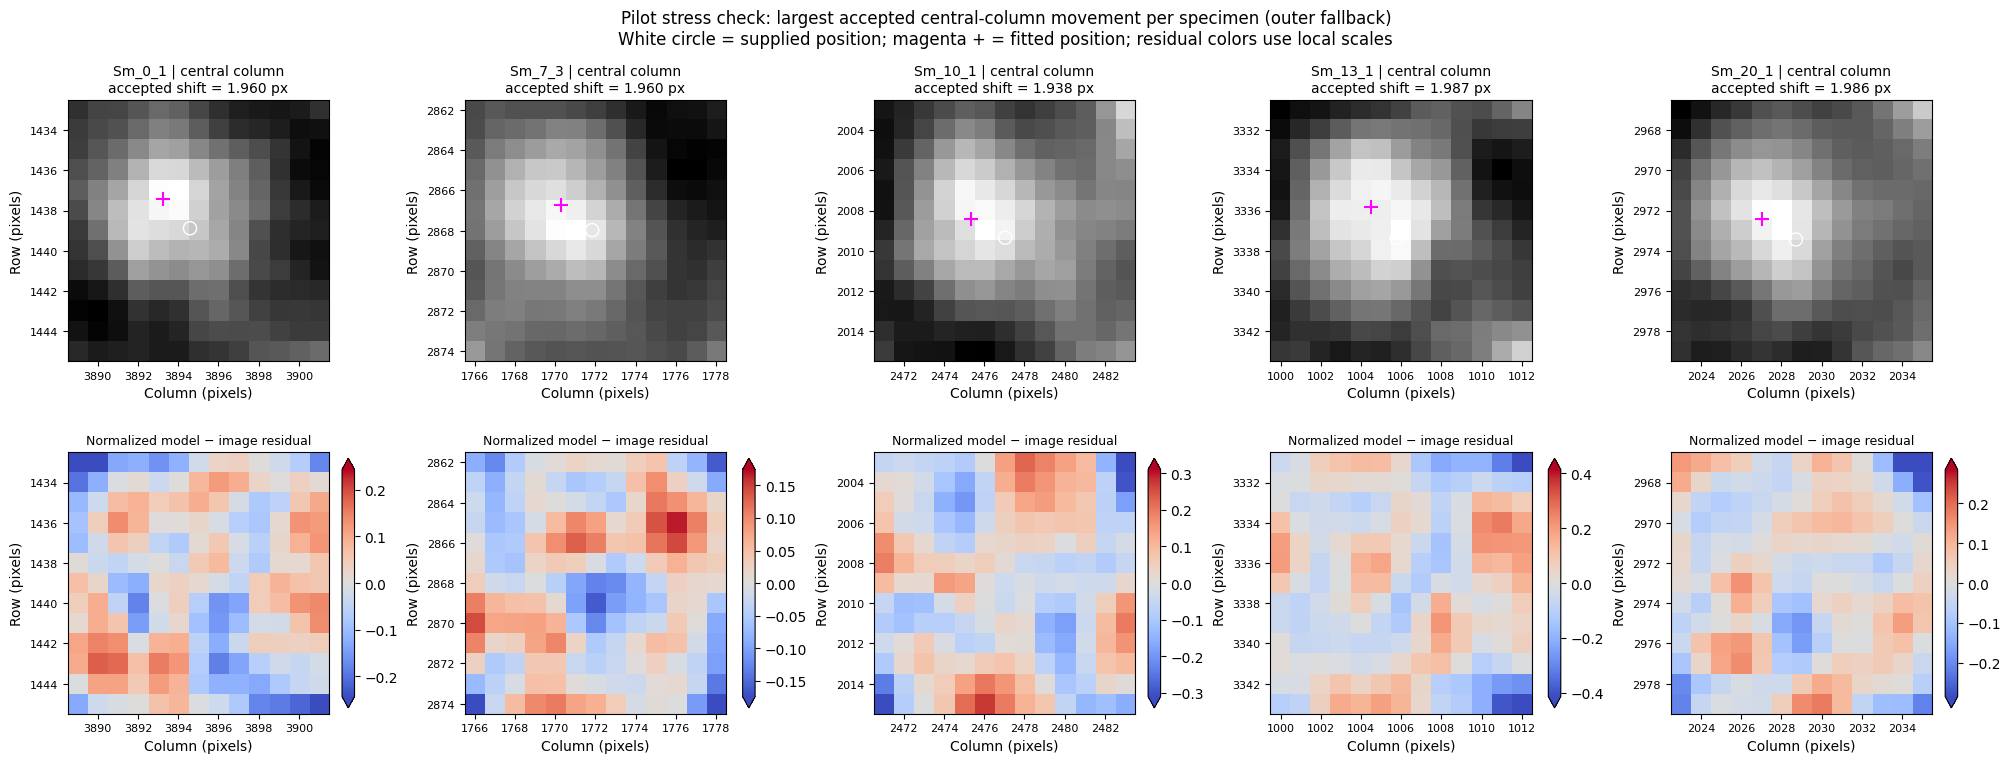

Approximate total full-fit time: 37.2 minutes (fit time only; rough estimate).
Saved pilot: /content/hackathon_outputs/block04_gaussian_pilot_20261106T213316_830978Z.npz
Saved figure: /content/hackathon_outputs/block04_gaussian_pilot_20261106T213316_830978Z.png
Block 4 complete. Baseline unchanged; this is a pilot, not a full refined map.


In [ ]:
# BLOCK 4B — Run a fixed, image-only localization pilot.

from collections import Counter
from datetime import datetime, timezone
from pathlib import Path
from time import perf_counter
import json
import h5py
import matplotlib.pyplot as plt
from scipy.spatial import cKDTree

if any(name not in globals() for name in [
    "hackathon_samples",
    "ha_baseline",
    "ha_geometry_audit",
    "ha_fit_gaussian_peak",
]):
    raise RuntimeError("Run Blocks 1–3 and Block 4A first.")

HA_PILOT_CELLS = 64
HA_PILOT_SEED = 20261106

ha_fit_settings = dict(
    max_axis_shift_px=2.,
    max_shift_px=2.,
    min_peak_to_residual=5.,
    bound_margin_px=.02,
    max_nfev=60,
)

ha_pilot_config = {
    "pilot_only": True,
    "reference_values_used": False,
    "model": "axis-aligned elliptical Gaussian plus planar background",
    "cells_per_sample": HA_PILOT_CELLS,
    "random_seed": HA_PILOT_SEED,
    "eligibility": (
        "finite in-bounds coordinates, convex cage, "
        "central atom inside/on cage"
    ),
    "radius_rule": (
        "clip(round(0.23 * median eligible cage-edge length), 4, 8) pixels"
    ),
    "neighbor_guard": (
        "skip seed if another column lies within "
        "sqrt(2)*(radius+0.5) pixels"
    ),
    "loss": "soft_l1",
    "f_scale_normalized": .1,
    "normalization": (
        "5th–95th percentile, range fallback; no pixel clipping"
    ),
    "width_bounds_px": "0.6 to 0.8*radius",
    "fit_settings": ha_fit_settings,
    "quality_thresholds": (
        "prespecified heuristics, not calibrated uncertainty estimates"
    ),
    "complete_cell": (
        "all five atomic fits accepted; failed positions are not substituted"
    ),
    "baseline_snapshot": str(
        globals().get("ha_snapshot_path", "unspecified")
    ),
}

ha_fit_pilot = {}

ha_pilot_samples = sorted(
    hackathon_samples,
    key=lambda s: (s["sm_percent"], s["sample_id"]),
)

ha_pilot_fig, ha_pilot_axes = plt.subplots(
    2,
    len(ha_pilot_samples),
    figsize=(4 * len(ha_pilot_samples), 7.6),
    squeeze=False,
    layout="constrained",
)

ha_full_minutes = 0.

print("GAUSSIAN LOCALIZATION PILOT — no reference values used")
print("Coordinate changes below are not accuracy improvements.\n")

for ha_col, ha_s in enumerate(ha_pilot_samples):
    ha_id = ha_s["sample_id"]
    ha_base = ha_baseline[ha_id]
    ha_geom = ha_geometry_audit[ha_id]

    np.testing.assert_array_equal(
        ha_s["cell_ids"], ha_base["cell_id"]
    )
    np.testing.assert_array_equal(
        ha_s["cell_ids"], ha_geom["cell_id"]
    )

    ha_eligible = np.flatnonzero(
        ha_base["valid"]
        & ha_geom["convex"]
        & ha_geom["inside"]
    )

    if not len(ha_eligible):
        for ha_ax in ha_pilot_axes[:, ha_col]:
            ha_ax.text(
                .5, .5, "No eligible cells",
                ha="center",
                transform=ha_ax.transAxes,
            )
        print(ha_id, "— no eligible cells")
        continue

    # Reproducible random sampling using geometry only.
    ha_rng = np.random.default_rng(
        HA_PILOT_SEED + int(ha_s["sm_percent"])
    )

    ha_chosen = np.sort(
        ha_rng.choice(
            ha_eligible,
            min(HA_PILOT_CELLS, len(ha_eligible)),
            replace=False,
        )
    )

    ha_radius = int(np.clip(
        np.rint(
            .23 * np.median(ha_geom["edge_px"][ha_eligible])
        ),
        4,
        8,
    ))

    ha_initial = ha_s["atoms_rc"][ha_chosen]

    # Fit each unique column once, then reuse it in shared cells.
    ha_unique, ha_inverse = np.unique(
        ha_initial.reshape(-1, 2),
        axis=0,
        return_inverse=True,
    )
    ha_inverse = ha_inverse.reshape(len(ha_chosen), 5)

    # Full unique-column count supports a realistic runtime estimate.
    ha_all_unique = np.unique(
        ha_s["atoms_rc"][ha_eligible].reshape(-1, 2),
        axis=0,
    )

    ha_nearest = cKDTree(ha_all_unique).query(
        ha_unique, k=2
    )[0][:, 1]

    ha_center_role = np.zeros(len(ha_unique), dtype=bool)
    ha_outer_role = np.zeros(len(ha_unique), dtype=bool)

    ha_center_role[ha_inverse[:, 4]] = True
    ha_outer_role[ha_inverse[:, :4].ravel()] = True

    with h5py.File(ha_s["image_path"], "r") as ha_f:
        ha_image = np.asarray(ha_f["MainImage"]).squeeze()

    if tuple(ha_image.shape) != tuple(ha_s["image_shape"]):
        raise ValueError(f"{ha_id}: unexpected image dimensions.")

    ha_results = []
    ha_t0 = perf_counter()

    for ha_seed, ha_nn in zip(ha_unique, ha_nearest):
        # Avoid fitting windows that could contain a nearby column.
        if ha_nn <= np.sqrt(2) * (ha_radius + .5):
            ha_result = dict(
                success=False,
                reason="neighbor_too_close",
                refined_rc=np.full(2, np.nan),
                shift_px=np.nan,
                residual_rms_normalized=np.nan,
                peak_to_residual_ratio=np.nan,
                fit_params=np.full(8, np.nan),
                nfev=0,
            )
        else:
            ha_result = ha_fit_gaussian_peak(
                ha_image,
                ha_seed,
                ha_radius,
                **ha_fit_settings,
            )

        ha_results.append(ha_result)

    ha_elapsed = perf_counter() - ha_t0

    ha_accepted = np.array(
        [r["success"] for r in ha_results],
        dtype=bool,
    )
    ha_positions = np.array(
        [r["refined_rc"] for r in ha_results]
    )
    ha_shifts = np.array(
        [r["shift_px"] for r in ha_results]
    )

    # Calculate a refined displacement only when all five fits pass.
    ha_complete = ha_accepted[ha_inverse].all(axis=1)
    ha_new_atoms = ha_positions[ha_inverse]

    ha_new_drc = np.full((len(ha_chosen), 2), np.nan)

    ha_new_drc[ha_complete] = (
        ha_new_atoms[ha_complete, 4]
        - ha_new_atoms[ha_complete, :4].mean(axis=1)
    )

    ha_base_drc = np.column_stack([
        ha_base["dy_px"][ha_chosen],
        ha_base["dx_px"][ha_chosen],
    ])

    ha_changes = np.linalg.norm(
        ha_new_drc - ha_base_drc,
        axis=1,
    )

    ha_estimate = (
        ha_elapsed
        * len(ha_all_unique)
        / max(len(ha_unique), 1)
        / 60
    )
    ha_full_minutes += ha_estimate

    ha_fit_pilot[ha_id] = {
        "sampled_cell_rows": ha_chosen,
        "cell_id": np.array(ha_s["cell_ids"])[ha_chosen],
        "unique_initial_rc": ha_unique,
        "unique_refined_rc": ha_positions,
        "cell_to_unique": ha_inverse,
        "accepted": ha_accepted,
        "central_role": ha_center_role,
        "outer_role": ha_outer_role,
        "candidate_shift_px": ha_shifts,
        "reason": np.array(
            [r["reason"] for r in ha_results], dtype="U200"
        ),
        "residual_rms_normalized": np.array([
            r["residual_rms_normalized"] for r in ha_results
        ]),
        "peak_to_residual_ratio": np.array([
            r["peak_to_residual_ratio"] for r in ha_results
        ]),
        "fit_params": np.array([
            r["fit_params"] for r in ha_results
        ]),
        "normalization_offset": np.array([
            r.get("normalization_offset", np.nan)
            for r in ha_results
        ]),
        "normalization_scale": np.array([
            r.get("normalization_scale", np.nan)
            for r in ha_results
        ]),
        "nfev": np.array([r["nfev"] for r in ha_results]),
        "complete_cell": ha_complete,
        "baseline_drc_px": ha_base_drc,
        "refined_drc_px": ha_new_drc,
        "vector_change_px": ha_changes,
        "patch_radius": np.asarray(ha_radius),
        "eligible_cells": np.asarray(len(ha_eligible)),
        "full_unique_columns": np.asarray(len(ha_all_unique)),
        "fit_seconds": np.asarray(ha_elapsed),
        "estimated_full_fit_minutes": np.asarray(ha_estimate),
    }

    print(
        f"{ha_id}: eligible cells "
        f"{len(ha_eligible):,}/{len(ha_base['valid']):,}; "
        f"sampled {len(ha_chosen)}; radius {ha_radius} px"
    )

    print(
        f"  Accepted unique columns: "
        f"{ha_accepted.sum()}/{len(ha_unique)}; "
        f"outer "
        f"{np.sum(ha_accepted & ha_outer_role)}/{ha_outer_role.sum()}; "
        f"central "
        f"{np.sum(ha_accepted & ha_center_role)}/{ha_center_role.sum()}"
    )

    print(
        "  Cells with all five fits accepted: "
        f"{ha_complete.sum()}/{len(ha_chosen)}"
    )

    if ha_accepted.any():
        print(
            "  Accepted column movement: "
            f"median {np.median(ha_shifts[ha_accepted]):.4f} px; "
            f"P95 "
            f"{np.percentile(ha_shifts[ha_accepted], 95):.4f} px"
        )

    if ha_complete.any():
        print(
            "  Vector change on complete cells: "
            f"median {np.median(ha_changes[ha_complete]):.4f} px; "
            f"P95 "
            f"{np.percentile(ha_changes[ha_complete], 95):.4f} px"
        )

        print(
            "  SAME complete cells, median |d|: baseline "
            f"{np.median(np.linalg.norm(ha_base_drc[ha_complete], axis=1)):.4f} px; "
            "refined "
            f"{np.median(np.linalg.norm(ha_new_drc[ha_complete], axis=1)):.4f} px"
        )

    print(
        "  Rejected reasons:",
        dict(Counter(
            r["reason"] for r in ha_results
            if not r["success"]
        )),
    )

    print(
        f"  Pilot fit time {ha_elapsed:.1f} s; "
        f"approximate full fit {ha_estimate:.1f} min "
        f"for {len(ha_all_unique):,} unique columns.\n",
        flush=True,
    )

    # Display the largest accepted central-column movement.
    # If no central fits pass, display an accepted outer-column fit.
    ha_show = np.flatnonzero(
        ha_accepted & ha_center_role
    )

    if not len(ha_show):
        ha_show = np.flatnonzero(ha_accepted)

    if len(ha_show):
        ha_j = ha_show[np.argmax(ha_shifts[ha_show])]
        ha_fit = ha_results[ha_j]

        ha_r0, ha_r1, ha_c0, ha_c1 = (
            ha_fit["patch_bounds_rc"]
        )

        ha_patch = np.asarray(
            ha_image[ha_r0:ha_r1, ha_c0:ha_c1],
            dtype=float,
        )
        ha_seed = ha_unique[ha_j]

        ha_rr, ha_cc = np.meshgrid(
            np.arange(ha_r0, ha_r1) - ha_seed[0],
            np.arange(ha_c0, ha_c1) - ha_seed[1],
            indexing="ij",
        )

        # Reconstruct the fitted model without fitting it again.
        ha_model, _ = _ha_gaussian_plane(
            ha_fit["fit_params"], ha_rr, ha_cc
        )

        ha_residual = ha_model - (
            (ha_patch - ha_fit["normalization_offset"])
            / ha_fit["normalization_scale"]
        )

        ha_extent = (
            ha_c0 - .5, ha_c1 - .5,
            ha_r1 - .5, ha_r0 - .5,
        )

        ha_ax = ha_pilot_axes[0, ha_col]

        ha_ax.imshow(
            ha_patch,
            cmap="gray",
            origin="upper",
            extent=ha_extent,
        )

        ha_ax.scatter(
            ha_seed[1], ha_seed[0],
            s=90,
            facecolors="none",
            edgecolors="white",
        )

        ha_ax.scatter(
            ha_positions[ha_j, 1],
            ha_positions[ha_j, 0],
            s=90,
            marker="+",
            c="magenta",
        )

        ha_role = (
            "central" if ha_center_role[ha_j] else "outer"
        )

        ha_ax.set_title(
            f"{ha_id} | {ha_role} column\n"
            f"accepted shift = {ha_shifts[ha_j]:.3f} px",
            fontsize=10,
        )

        ha_lim = max(
            float(np.percentile(np.abs(ha_residual), 99)),
            1e-6,
        )

        ha_artist = ha_pilot_axes[1, ha_col].imshow(
            ha_residual,
            cmap="coolwarm",
            origin="upper",
            extent=ha_extent,
            vmin=-ha_lim,
            vmax=ha_lim,
        )

        ha_pilot_axes[1, ha_col].set_title(
            "Normalized model − image residual",
            fontsize=9,
        )

        ha_pilot_fig.colorbar(
            ha_artist,
            ax=ha_pilot_axes[1, ha_col],
            shrink=.75,
            extend="both",
        )

    else:
        for ha_ax in ha_pilot_axes[:, ha_col]:
            ha_ax.text(
                .5, .5, "No accepted fit",
                ha="center",
                va="center",
                transform=ha_ax.transAxes,
            )

    for ha_ax in ha_pilot_axes[:, ha_col]:
        ha_ax.set_xlabel("Column (pixels)")
        ha_ax.set_ylabel("Row (pixels)")
        ha_ax.tick_params(labelsize=8)

    del ha_image


ha_pilot_fig.suptitle(
    "Pilot stress check: largest accepted central-column movement "
    "per specimen (outer fallback)\n"
    "White circle = supplied position; magenta + = fitted position; "
    "residual colors use local scales",
    fontsize=12,
)

ha_pilot_dir = Path("hackathon_outputs")
ha_pilot_dir.mkdir(parents=True, exist_ok=True)

ha_pilot_stem = (
    "block04_gaussian_pilot_"
    + datetime.now(timezone.utc).strftime(
        "%Y%m%dT%H%M%S_%fZ"
    )
)

ha_pilot_fig_path = ha_pilot_dir / f"{ha_pilot_stem}.png"
ha_pilot_fig.savefig(ha_pilot_fig_path, dpi=180)

plt.show()

ha_pilot_archive = {
    "config_json": np.asarray(
        json.dumps(ha_pilot_config, indent=2)
    )
}

for ha_id, ha_record in ha_fit_pilot.items():
    for ha_key, ha_value in ha_record.items():
        ha_pilot_archive[f"{ha_id}__{ha_key}"] = ha_value

ha_pilot_path = ha_pilot_dir / f"{ha_pilot_stem}.npz"
np.savez_compressed(
    ha_pilot_path, **ha_pilot_archive
)

print(
    f"Approximate total full-fit time: "
    f"{ha_full_minutes:.1f} minutes "
    "(fit time only; rough estimate)."
)

print("Saved pilot:", ha_pilot_path.resolve())
print("Saved figure:", ha_pilot_fig_path.resolve())
print(
    "Block 4 complete. Baseline unchanged; "
    "this is a pilot, not a full refined map."
)

Evaluation plan saved before loading Pxy.
Frozen baseline SHA-256: eb4cb9e64fc48307222e834ff87f4ff99adcb80564c518857f27c6a440152411
Pairing: dx ↔ Pxy[0]; dy ↔ Pxy[1]. Reference sign and units remain unverified.

FINAL COMPONENT ASSOCIATIONS — not calibrated displacement errors

Population: all_coordinate_valid
Sample            N x      N y       r x     rho x       r y     rho y
Sm_0_1          23541    23541   -0.1314   -0.0167   -0.1314   -0.0167
Sm_7_3          23074    23074   -0.7367   -0.7488   -0.7367   -0.7488
Sm_10_1         22949    22949    0.4440    0.4911    0.4440    0.4911
Sm_13_1         20510    20510   -0.1345    0.1631   -0.1345    0.1631
Sm_20_1         18390    18390    0.1157    0.1059    0.1157    0.1059

Population: geometry_inside
Sample            N x      N y       r x     rho x       r y     rho y
Sm_0_1          23535    23535   -0.1311   -0.0163   -0.1311   -0.0163
Sm_7_3          23074    23074   -0.7367   -0.7488   -0.7367   -0.7488
Sm_10_1         2294

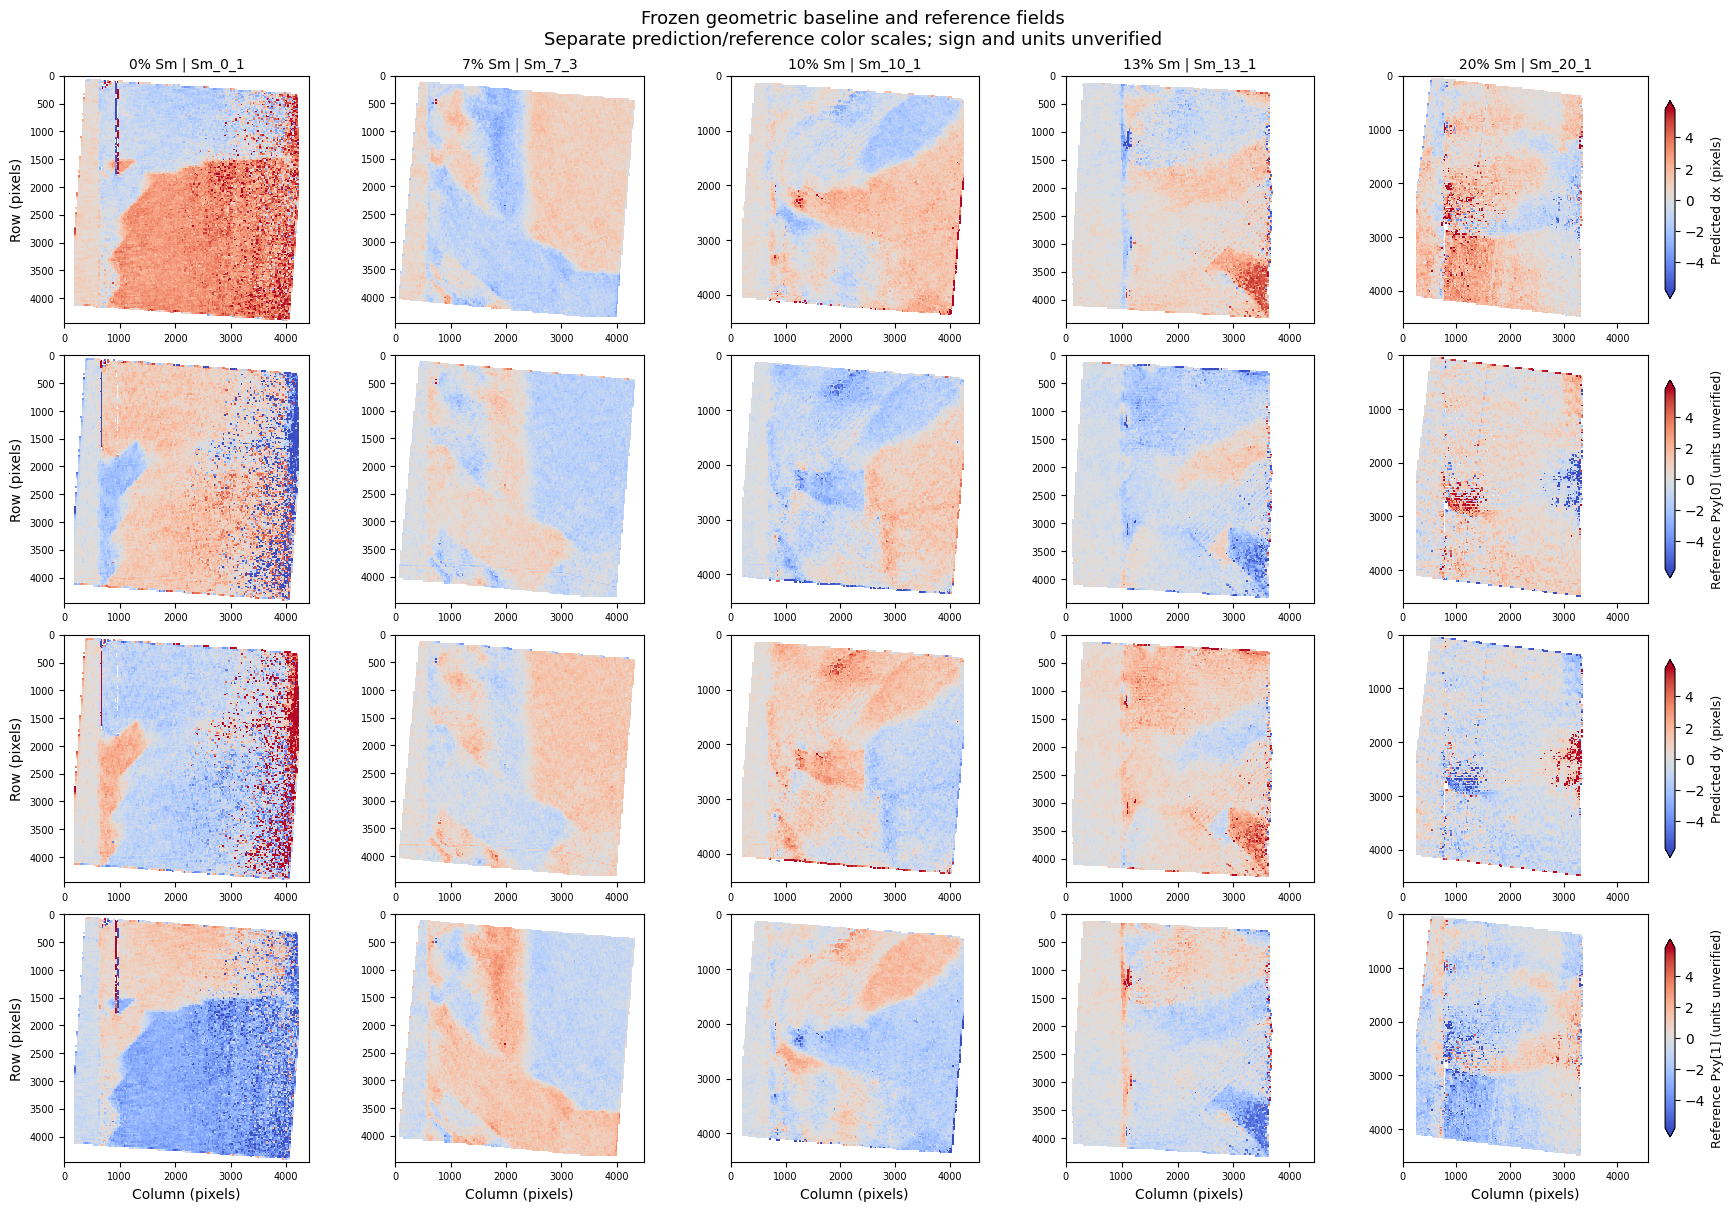

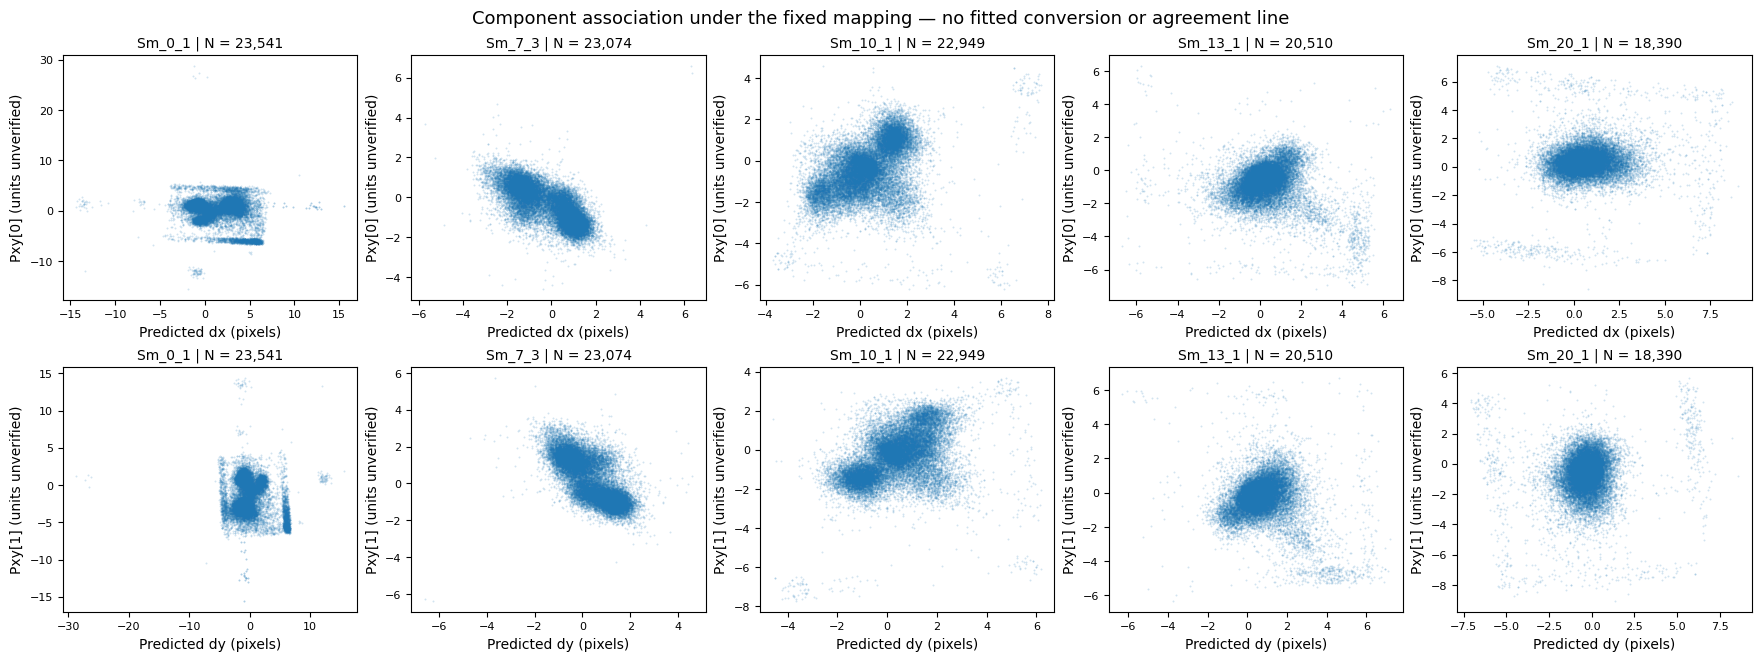


HACKATHON RESULTS — GEOMETRIC DISPLACEMENT RECONSTRUCTION
Original cells: 108,464; geometry-inside cells: 108,458.
Method: central position 5 minus the arithmetic mean of surrounding positions 1–4.
Coordinates: dx is increasing column; dy is increasing row. Units: image pixels.
The supplied xy_COM equals the arithmetic mean of all five positions.
No reference polarization values were used to train, tune, or select the primary method.
Gaussian pilot: 69/320 complete cells (21.6%); estimated full-fit time 37.2 min.
The bounded Gaussian pilot was not promoted to a full reconstruction.
Accepted-fit coordinate shifts are recorded in image_fitting_pilot.csv.
An absolute coordinate-origin difference is unresolved; a uniform translation cancels in the geometric displacement.
Final evaluation: signed component Pearson/Spearman associations under dx↔Pxy[0], dy↔Pxy[1].
Reference sign and units were not independently documented. These scores do not establish calibrated displacement accuracy.
No r

In [ ]:
# BLOCK 5 — Final evaluation of the frozen baseline and submission package.
# Pxy is read ONLY after the evaluation plan and prediction hashes are saved.

from pathlib import Path
from datetime import datetime, timezone
import csv
import hashlib
import json
import re
import shutil
import zipfile
import h5py
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

if any(k not in globals() for k in [
    "hackathon_samples",
    "ha_snapshot_path",
    "ha_b3_npz",
    "ha_fit_pilot",
]):
    raise RuntimeError("Run Blocks 1–4 first.")


def ha_signed_correlations(prediction, reference, population):
    paired = (
        population
        & np.isfinite(prediction)
        & np.isfinite(reference)
    )
    x, y = prediction[paired], reference[paired]

    if len(x) < 3:
        return len(x), np.nan, np.nan

    sx, sy = np.max(np.abs(x)), np.max(np.abs(y))

    if sx == 0 or sy == 0:
        return len(x), np.nan, np.nan

    xs, ys = x / sx, y / sy

    # Constant/numerically degenerate components have
    # undefined correlation.
    tol = 32 * np.finfo(float).eps

    if np.ptp(xs) <= tol or np.ptp(ys) <= tol:
        return len(x), np.nan, np.nan

    return (
        len(x),
        float(np.corrcoef(xs, ys)[0, 1]),
        float(spearmanr(x, y).statistic),
    )


def ha_write_csv(path, records):
    if records:
        with path.open("w", newline="", encoding="utf-8") as f:
            writer = csv.DictWriter(
                f, fieldnames=list(records[0])
            )
            writer.writeheader()
            writer.writerows(records)


# ------------------------------------------------------------
# 1. Reload the frozen prediction and geometry checkpoints.
# ------------------------------------------------------------

ha_eval_baseline_file = Path(ha_snapshot_path)
ha_eval_geometry_file = Path(ha_b3_npz)

ha_eval_samples = sorted(
    hackathon_samples,
    key=lambda s: (s["sm_percent"], s["sample_id"]),
)

ha_eval_frozen = {}

with np.load(
    ha_eval_baseline_file, allow_pickle=False
) as z, np.load(
    ha_eval_geometry_file, allow_pickle=False
) as g:

    ha_frozen_config = json.loads(z["config_json"].item())

    if ha_frozen_config.get("reference_values_used") is not False:
        raise ValueError(
            "The baseline archive does not identify "
            "an independent prediction run."
        )

    for ha_s in ha_eval_samples:
        ha_id = ha_s["sample_id"]

        ha_r = {
            k: np.array(z[f"{ha_id}__{k}"], copy=True)
            for k in [
                "cell_id",
                "dx_px",
                "dy_px",
                "valid",
                "map_valid",
                "map_rc",
                "image_shape",
            ]
        }

        np.testing.assert_array_equal(
            ha_r["cell_id"], ha_s["cell_ids"]
        )
        np.testing.assert_array_equal(
            ha_r["cell_id"], g[f"{ha_id}__cell_id"]
        )

        ha_r["geometry_inside"] = (
            ha_r["valid"]
            & g[f"{ha_id}__convex"]
            & g[f"{ha_id}__inside"]
        )

        ha_eval_frozen[ha_id] = ha_r


# ------------------------------------------------------------
# 2. Record the pilot outcome and evaluation choices.
#    No reference values have been read by this block yet.
# ------------------------------------------------------------

ha_pilot_report = []

for ha_s in ha_eval_samples:
    ha_id = ha_s["sample_id"]
    ha_p = ha_fit_pilot[ha_id]
    ha_good = ha_p["accepted"]

    ha_shift = (
        ha_p["unique_refined_rc"]
        - ha_p["unique_initial_rc"]
    )

    ha_pilot_report.append({
        "sample": ha_id,
        "sampled_cells": int(len(ha_p["cell_id"])),
        "complete_cells": int(ha_p["complete_cell"].sum()),
        "complete_percent": float(
            100 * ha_p["complete_cell"].mean()
        ),
        "accepted_unique_columns": int(ha_good.sum()),
        "attempted_unique_columns": int(len(ha_good)),
        "median_accepted_row_shift_px": (
            float(np.median(ha_shift[ha_good, 0]))
            if ha_good.any() else np.nan
        ),
        "median_accepted_column_shift_px": (
            float(np.median(ha_shift[ha_good, 1]))
            if ha_good.any() else np.nan
        ),
        "estimated_full_fit_minutes": float(
            ha_p["estimated_full_fit_minutes"]
        ),
    })

ha_eval_stamp = datetime.now(timezone.utc).strftime(
    "%Y%m%dT%H%M%S_%fZ"
)

ha_final_dir = (
    Path("hackathon_outputs")
    / f"final_submission_{ha_eval_stamp}"
)
ha_final_dir.mkdir(parents=True, exist_ok=False)

ha_eval_plan = {
    "primary_method": (
        "frozen central atom 5 minus "
        "arithmetic mean of atoms 1–4"
    ),
    "selection_reason": (
        "limited complete-cell coverage and runtime "
        "of image-only Gaussian pilot"
    ),
    "baseline_file": ha_eval_baseline_file.name,
    "baseline_sha256": hashlib.sha256(
        ha_eval_baseline_file.read_bytes()
    ).hexdigest(),
    "geometry_file": ha_eval_geometry_file.name,
    "geometry_sha256": hashlib.sha256(
        ha_eval_geometry_file.read_bytes()
    ).hexdigest(),
    "pairing_fixed_before_reference_read": {
        "dx_px": "Pxy[0]; increasing column direction",
        "dy_px": "Pxy[1]; increasing row direction",
    },
    "reference_convention_status": (
        "sign and units not independently documented"
    ),
    "primary_population": (
        "all baseline coordinate-valid cells; "
        "finite pairs per component"
    ),
    "secondary_population": (
        "previously defined convex cages "
        "with atom 5 inside/on cage"
    ),
    "metrics": (
        "signed Pearson and Spearman component associations; "
        "no independent-cell significance tests"
    ),
    "withheld_metrics": (
        "MAE, RMSE, R-squared, angular accuracy; "
        "convention/calibration unverified"
    ),
    "no_reference_based_adjustment": (
        "no sign changes, axis searches, scale fits, "
        "offsets, or new exclusions"
    ),
    "created_utc_before_reference_read": (
        datetime.now(timezone.utc).isoformat()
    ),
}

(ha_final_dir / "evaluation_plan.json").write_text(
    json.dumps(ha_eval_plan, indent=2),
    encoding="utf-8",
)

ha_write_csv(
    ha_final_dir / "image_fitting_pilot.csv",
    ha_pilot_report,
)

print("Evaluation plan saved before loading Pxy.")
print(
    "Frozen baseline SHA-256:",
    ha_eval_plan["baseline_sha256"],
)
print(
    "Pairing: dx ↔ Pxy[0]; dy ↔ Pxy[1]. "
    "Reference sign and units remain unverified.\n"
)


# ------------------------------------------------------------
# 3. Load the reference for final evaluation.
#    Predictions, pairing, and masks are already fixed.
# ------------------------------------------------------------

ha_evaluation = {}
ha_eval_rows = []

for ha_s in ha_eval_samples:
    ha_id = ha_s["sample_id"]
    ha_r = dict(ha_eval_frozen[ha_id])
    ha_n = len(ha_r["cell_id"])

    with h5py.File(ha_s["parameter_path"], "r") as ha_f:
        ha_raw = np.asarray(ha_f["Pxy"], dtype=float)

    if ha_raw.shape == (2, ha_n):
        ha_ref = ha_raw.T
    elif ha_raw.shape == (ha_n, 2):
        ha_ref = ha_raw
    else:
        raise ValueError(
            f"{ha_id}: Pxy shape {ha_raw.shape} "
            f"does not match {ha_n} original cells."
        )

    if not np.array_equal(
        ha_r["cell_id"], np.arange(ha_n)
    ):
        raise ValueError(
            f"{ha_id}: unexpected original cell indexing; "
            "do not realign by target values."
        )

    ha_r["reference_xy"] = ha_ref
    ha_evaluation[ha_id] = ha_r

    for ha_label, ha_population in [
        ("all_coordinate_valid", ha_r["valid"]),
        ("geometry_inside", ha_r["geometry_inside"]),
    ]:
        ha_nx, ha_rx, ha_sx = ha_signed_correlations(
            ha_r["dx_px"], ha_ref[:, 0], ha_population
        )
        ha_ny, ha_ry, ha_sy = ha_signed_correlations(
            ha_r["dy_px"], ha_ref[:, 1], ha_population
        )

        ha_eval_rows.append({
            "sample": ha_id,
            "sm_percent": int(ha_s["sm_percent"]),
            "population": ha_label,
            "original_cells": ha_n,
            "population_cells": int(ha_population.sum()),
            "paired_x": ha_nx,
            "paired_y": ha_ny,
            "coverage_x_percent": 100 * ha_nx / ha_n,
            "coverage_y_percent": 100 * ha_ny / ha_n,
            "pearson_x": ha_rx,
            "spearman_x": ha_sx,
            "pearson_y": ha_ry,
            "spearman_y": ha_sy,
        })

ha_write_csv(
    ha_final_dir / "component_correlations.csv",
    ha_eval_rows,
)

print(
    "FINAL COMPONENT ASSOCIATIONS — "
    "not calibrated displacement errors"
)

for ha_population in [
    "all_coordinate_valid",
    "geometry_inside",
]:
    print("\nPopulation:", ha_population)
    print(
        f"{'Sample':<12} {'N x':>8} {'N y':>8} "
        f"{'r x':>9} {'rho x':>9} "
        f"{'r y':>9} {'rho y':>9}"
    )

    for ha_row in ha_eval_rows:
        if ha_row["population"] == ha_population:
            print(
                f"{ha_row['sample']:<12} "
                f"{ha_row['paired_x']:8d} "
                f"{ha_row['paired_y']:8d} "
                f"{ha_row['pearson_x']:9.4f} "
                f"{ha_row['spearman_x']:9.4f} "
                f"{ha_row['pearson_y']:9.4f} "
                f"{ha_row['spearman_y']:9.4f}"
            )

print(
    "\nNaN means undefined correlation, such as a constant "
    "component or fewer than three finite pairs."
)


# ------------------------------------------------------------
# 4. Plot predictions and references on separate color scales.
# ------------------------------------------------------------

ha_pred_pool, ha_ref_pool = [], []

for ha_r in ha_evaluation.values():
    for ha_k, ha_key in enumerate(["dx_px", "dy_px"]):
        ha_m = (
            ha_r["map_valid"]
            & np.isfinite(ha_r[ha_key])
            & np.isfinite(ha_r["reference_xy"][:, ha_k])
        )

        if ha_m.any():
            ha_pred_pool.append(
                np.abs(ha_r[ha_key][ha_m])
            )
            ha_ref_pool.append(
                np.abs(ha_r["reference_xy"][ha_m, ha_k])
            )

ha_pred_lim = (
    float(np.percentile(np.concatenate(ha_pred_pool), 99))
    or 1.
) if ha_pred_pool else 1.

ha_ref_lim = (
    float(np.percentile(np.concatenate(ha_ref_pool), 99))
    or 1.
) if ha_ref_pool else 1.

ha_compare_fig, ha_compare_axes = plt.subplots(
    4,
    len(ha_eval_samples),
    figsize=(3.5 * len(ha_eval_samples), 12),
    squeeze=False,
    layout="constrained",
)

ha_scatter_fig, ha_scatter_axes = plt.subplots(
    2,
    len(ha_eval_samples),
    figsize=(3.5 * len(ha_eval_samples), 6.5),
    squeeze=False,
    layout="constrained",
)

ha_map_labels = [
    "Predicted dx (pixels)",
    "Reference Pxy[0] (units unverified)",
    "Predicted dy (pixels)",
    "Reference Pxy[1] (units unverified)",
]

for ha_col, ha_s in enumerate(ha_eval_samples):
    ha_id = ha_s["sample_id"]
    ha_r = ha_evaluation[ha_id]

    for ha_k, ha_key in enumerate(["dx_px", "dy_px"]):
        ha_pred = ha_r[ha_key]
        ha_ref = ha_r["reference_xy"][:, ha_k]

        ha_pairs = (
            ha_r["valid"]
            & np.isfinite(ha_pred)
            & np.isfinite(ha_ref)
        )
        ha_m = ha_pairs & ha_r["map_valid"]
        ha_xy = ha_r["map_rc"][ha_m]

        for ha_offset, ha_values, ha_lim in [
            (0, ha_pred, ha_pred_lim),
            (1, ha_ref, ha_ref_lim),
        ]:
            ha_ax = ha_compare_axes[
                2 * ha_k + ha_offset, ha_col
            ]

            ha_artist = ha_ax.scatter(
                ha_xy[:, 1],
                ha_xy[:, 0],
                c=ha_values[ha_m],
                s=2,
                marker="s",
                linewidths=0,
                cmap="coolwarm",
                vmin=-ha_lim,
                vmax=ha_lim,
                rasterized=True,
            )

            ha_h, ha_w = ha_r["image_shape"]

            ha_ax.set(
                xlim=(0, ha_w - 1),
                ylim=(ha_h - 1, 0),
                aspect="equal",
            )
            ha_ax.tick_params(labelsize=7)

            if ha_k == 0 and ha_offset == 0:
                ha_ax.set_title(
                    f"{ha_s['sm_percent']}% Sm | {ha_id}",
                    fontsize=10,
                )

            if ha_col == 0:
                ha_ax.set_ylabel("Row (pixels)")

            if ha_k == 1 and ha_offset == 1:
                ha_ax.set_xlabel("Column (pixels)")

            if ha_col == len(ha_eval_samples) - 1:
                ha_cb = ha_compare_fig.colorbar(
                    ha_artist,
                    ax=ha_compare_axes[
                        2 * ha_k + ha_offset, :
                    ].tolist(),
                    shrink=.8,
                    pad=.01,
                    extend="both",
                )

                ha_cb.set_label(
                    ha_map_labels[2 * ha_k + ha_offset],
                    fontsize=9,
                )

        ha_ax = ha_scatter_axes[ha_k, ha_col]

        ha_ax.scatter(
            ha_pred[ha_pairs],
            ha_ref[ha_pairs],
            s=2,
            alpha=.2,
            linewidths=0,
            rasterized=True,
        )

        ha_ax.set_title(
            f"{ha_id} | N = {ha_pairs.sum():,}",
            fontsize=10,
        )
        ha_ax.set_xlabel(
            f"Predicted {ha_key.removesuffix('_px')} (pixels)"
        )
        ha_ax.set_ylabel(
            f"Pxy[{ha_k}] (units unverified)"
        )
        ha_ax.tick_params(labelsize=8)

ha_compare_fig.suptitle(
    "Frozen geometric baseline and reference fields\n"
    "Separate prediction/reference color scales; "
    "sign and units unverified",
    fontsize=13,
)

ha_scatter_fig.suptitle(
    "Component association under the fixed mapping — "
    "no fitted conversion or agreement line",
    fontsize=13,
)

ha_compare_fig.savefig(
    ha_final_dir / "predicted_and_reference_maps.png",
    dpi=180,
)
ha_scatter_fig.savefig(
    ha_final_dir / "component_scatter.png",
    dpi=180,
)

plt.show()


# ------------------------------------------------------------
# 5. Save matched values as evaluation-only data.
# ------------------------------------------------------------

ha_matches = {}

for ha_id, ha_r in ha_evaluation.items():
    for ha_key in [
        "cell_id",
        "dx_px",
        "dy_px",
        "reference_xy",
        "valid",
        "geometry_inside",
    ]:
        ha_matches[f"{ha_id}__{ha_key}"] = ha_r[ha_key]

np.savez_compressed(
    ha_final_dir / "EVALUATION_ONLY_matched_values.npz",
    **ha_matches,
)


# ------------------------------------------------------------
# 6. Capture our executed code blocks in dependency order.
#    Unrelated notebook history is not included.
# ------------------------------------------------------------

ha_required = {"1", "2", "3", "4A", "4B", "5"}
ha_latest = {}

try:
    ha_history = get_ipython().history_manager.input_hist_raw
except (NameError, AttributeError):
    ha_history = []

for ha_i, ha_source in enumerate(ha_history):
    ha_markers = list(re.finditer(
        r"(?m)^[ \t]*#\s*BLOCK\s+(1|2|3|4A|4B|5)\b",
        ha_source,
    ))

    for ha_j, ha_marker in enumerate(ha_markers):
        ha_end = (
            ha_markers[ha_j + 1].start()
            if ha_j + 1 < len(ha_markers)
            else len(ha_source)
        )

        ha_section = ha_source[
            ha_marker.start():ha_end
        ]

        if (
            ha_j == 0
            and ha_source[:ha_marker.start()].strip()
        ):
            ha_section = (
                ha_source[:ha_marker.start()]
                + ha_section
            )

        ha_latest[ha_marker.group(1)] = ha_section

ha_missing = sorted(ha_required - set(ha_latest))

ha_selected_sources = [
    ha_latest[t]
    for t in ["1", "2", "3", "4A", "4B", "5"]
    if t in ha_latest
]

ha_cells = [
    {
        "cell_type": "markdown",
        "id": "instructions",
        "metadata": {},
        "source": [
            "# Geometric reconstruction of local atomic displacements\n",
            "Place the five original HAADF/UCParameterization file pairs "
            "in data_small, then run in order.\n",
            "Reference values are used only in the final evaluation. "
            "Reference sign and units remain unverified.\n",
            "This notebook was assembled from the executed challenge "
            "code blocks.\n",
        ],
    },
    {
        "cell_type": "code",
        "id": "data-folder",
        "metadata": {},
        "execution_count": None,
        "outputs": [],
        "source": ["filedir = 'data_small'\n"],
    },
]

for ha_i, ha_source in enumerate(ha_selected_sources):
    ha_cells.append({
        "cell_type": "code",
        "id": f"executed-block-{ha_i}",
        "metadata": {},
        "execution_count": None,
        "outputs": [],
        "source": ha_source.splitlines(keepends=True),
    })

ha_notebook_name = (
    "reproducible_workflow.ipynb"
    if not ha_missing
    else "captured_blocks_INCOMPLETE.ipynb"
)

(ha_final_dir / ha_notebook_name).write_text(
    json.dumps({
        "nbformat": 4,
        "nbformat_minor": 5,
        "metadata": {
            "kernelspec": {
                "name": "python3",
                "display_name": "Python 3",
                "language": "python",
            }
        },
        "cells": ha_cells,
    }, indent=1),
    encoding="utf-8",
)


# ------------------------------------------------------------
# 7. Write the results summary.
# ------------------------------------------------------------

ha_total = sum(
    len(r["cell_id"]) for r in ha_eval_frozen.values()
)
ha_inside = sum(
    int(r["geometry_inside"].sum())
    for r in ha_eval_frozen.values()
)

ha_pilot_n = sum(
    r["sampled_cells"] for r in ha_pilot_report
)
ha_pilot_complete = sum(
    r["complete_cells"] for r in ha_pilot_report
)

ha_summary = [
    "HACKATHON RESULTS — GEOMETRIC DISPLACEMENT RECONSTRUCTION",
    f"Original cells: {ha_total:,}; "
    f"geometry-inside cells: {ha_inside:,}.",
    "Method: central position 5 minus the arithmetic mean "
    "of surrounding positions 1–4.",
    "Coordinates: dx is increasing column; dy is increasing row. "
    "Units: image pixels.",
    "The supplied xy_COM equals the arithmetic mean "
    "of all five positions.",
    "No reference polarization values were used to train, tune, "
    "or select the primary method.",
    f"Gaussian pilot: {ha_pilot_complete}/{ha_pilot_n} complete cells "
    f"({100 * ha_pilot_complete / max(ha_pilot_n, 1):.1f}%); "
    "estimated full-fit time "
    f"{sum(r['estimated_full_fit_minutes'] for r in ha_pilot_report):.1f} min.",
    "The bounded Gaussian pilot was not promoted to a full reconstruction.",
    "Accepted-fit coordinate shifts are recorded "
    "in image_fitting_pilot.csv.",
    "An absolute coordinate-origin difference is unresolved; "
    "a uniform translation cancels in the geometric displacement.",
    "Final evaluation: signed component Pearson/Spearman associations "
    "under dx↔Pxy[0], dy↔Pxy[1].",
    "Reference sign and units were not independently documented. "
    "These scores do not establish calibrated displacement accuracy.",
    "No reference-derived flips, permutations, scales, offsets, "
    "or new quality exclusions were applied.",
    "MAE/RMSE, prediction R-squared, angular accuracy, "
    "and significance claims are omitted.",
    "Primary results retain all coordinate-valid cells; "
    "the original geometry-inside mask is a secondary stratum.",
    "Correlations describe these images; spatially adjacent cells "
    "are not independent specimen replicates.",
    "Required raw HDF5 files are not included. "
    "Use the original challenge data and the included workflow.",
    "Dependencies: Python, numpy, scipy, matplotlib, h5py; "
    "no GPU is required for the baseline.",
    "",
    "PRIMARY COMPONENT ASSOCIATIONS:",
]

for ha_row in ha_eval_rows:
    if ha_row["population"] == "all_coordinate_valid":
        ha_summary.append(
            f"{ha_row['sample']}: "
            f"x N={ha_row['paired_x']}, "
            f"r={ha_row['pearson_x']:.6f}, "
            f"rho={ha_row['spearman_x']:.6f}; "
            f"y N={ha_row['paired_y']}, "
            f"r={ha_row['pearson_y']:.6f}, "
            f"rho={ha_row['spearman_y']:.6f}."
        )

if ha_missing:
    ha_summary.append(
        "SOURCE CAPTURE INCOMPLETE — missing blocks: "
        + ", ".join(ha_missing)
        + ". Add your full executed notebook to the package."
    )

(ha_final_dir / "README_results.txt").write_text(
    "\n".join(ha_summary),
    encoding="utf-8",
)


# ------------------------------------------------------------
# 8. Package this run's results and checkpoints.
# ------------------------------------------------------------

for ha_source_path in [
    ha_eval_baseline_file,
    ha_eval_geometry_file,
    globals().get("ha_map_path"),
    globals().get("ha_b3_png"),
    globals().get("ha_pilot_path"),
    globals().get("ha_pilot_fig_path"),
]:
    if (
        ha_source_path is not None
        and Path(ha_source_path).is_file()
    ):
        shutil.copy2(
            ha_source_path,
            ha_final_dir / Path(ha_source_path).name,
        )

ha_submission_zip = ha_final_dir.with_suffix(".zip")

with zipfile.ZipFile(
    ha_submission_zip,
    "w",
    compression=zipfile.ZIP_DEFLATED,
) as ha_zip:
    for ha_file in sorted(ha_final_dir.iterdir()):
        if ha_file.is_file():
            ha_zip.write(
                ha_file,
                arcname=ha_file.name,
            )

print("\n" + "\n".join(ha_summary))
print("\nSubmission ZIP:", ha_submission_zip.resolve())
print("Captured workflow:", ha_notebook_name)
print("Final evaluation complete. Keep the evaluated predictions fixed.")

# To download the ZIP in Colab, run these two lines in another cell:
# from google.colab import files
# files.download(str(ha_submission_zip))

In [ ]:
# BLOCK 6 — Post-evaluation convention audit; frozen predictions stay unchanged.
# The hypothesis below was suggested by inspecting the Block 5 reference plots.
# These are numerical identity diagnostics, not new calibrated accuracy scores.

from pathlib import Path
from datetime import datetime, timezone
import csv
import hashlib
import json
import h5py
import numpy as np
from scipy.stats import spearmanr

if any(k not in globals() for k in ["ha_final_dir", "ha_snapshot_path", "hackathon_samples"]):
    raise RuntimeError("Run Block 5 first, in the same notebook session.")


def ha6_sha256(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()


def ha6_correlations(a, b, population):
    mask = population & np.isfinite(a) & np.isfinite(b)
    x, y = a[mask], b[mask]
    if len(x) < 3:
        return int(mask.sum()), np.nan, np.nan
    sx, sy = np.max(np.abs(x)), np.max(np.abs(y))
    if sx == 0 or sy == 0:
        return int(mask.sum()), np.nan, np.nan
    xs, ys = x/sx, y/sy
    # Keep Block 5's treatment of constant/numerically degenerate components.
    tol = 32*np.finfo(float).eps
    if np.ptp(xs) <= tol or np.ptp(ys) <= tol:
        return int(mask.sum()), np.nan, np.nan
    return int(mask.sum()), float(np.corrcoef(xs, ys)[0, 1]), float(spearmanr(x, y).statistic)


ha6_final = Path(ha_final_dir)
ha6_snapshot = Path(ha_snapshot_path)
ha6_matches = ha6_final / "EVALUATION_ONLY_matched_values.npz"
ha6_plan = json.loads((ha6_final / "evaluation_plan.json").read_text())
ha6_original_hash = ha6_sha256(ha6_snapshot)
if ha6_original_hash != ha6_plan["baseline_sha256"]:
    raise ValueError("Baseline hash differs from the saved evaluation plan. Stop and inspect the files.")
with (ha6_final / "component_correlations.csv").open(newline="") as ha6_f:
    ha6_old = {r["sample"]: r for r in csv.DictReader(ha6_f)
               if r["population"] == "all_coordinate_valid"}

ha6_records = []
with np.load(ha6_snapshot, allow_pickle=False) as ha6_b, np.load(ha6_matches, allow_pickle=False) as ha6_e:
    for ha6_s in sorted(hackathon_samples, key=lambda s: (s["sm_percent"], s["sample_id"])):
        ha6_id = ha6_s["sample_id"]
        # Verify exact prediction arrays, cell indexing, and the original mask.
        for ha6_key in ["cell_id", "dx_px", "dy_px", "valid"]:
            np.testing.assert_array_equal(ha6_b[f"{ha6_id}__{ha6_key}"],
                                          ha6_e[f"{ha6_id}__{ha6_key}"])
        ha6_ids = ha6_b[f"{ha6_id}__cell_id"]
        np.testing.assert_array_equal(ha6_ids, ha6_s["cell_ids"])
        ha6_n = len(ha6_ids)
        ha6_dx = np.asarray(ha6_b[f"{ha6_id}__dx_px"], dtype=float)
        ha6_dy = np.asarray(ha6_b[f"{ha6_id}__dy_px"], dtype=float)
        ha6_valid = np.asarray(ha6_b[f"{ha6_id}__valid"], dtype=bool)
        ha6_ref = np.asarray(ha6_e[f"{ha6_id}__reference_xy"], dtype=float)
        if ha6_dx.shape != (ha6_n,) or ha6_dy.shape != (ha6_n,) or ha6_ref.shape != (ha6_n, 2):
            raise ValueError(f"{ha6_id}: unexpected saved component shape.")
        # Re-read Pxy only to check the saved evaluation values and column order.
        with h5py.File(ha6_s["parameter_path"], "r") as ha6_f:
            ha6_raw = np.asarray(ha6_f["Pxy"], dtype=float)
        if ha6_raw.shape == (2, ha6_n):
            ha6_raw = ha6_raw.T
        elif ha6_raw.shape != (ha6_n, 2):
            raise ValueError(f"{ha6_id}: unexpected source Pxy shape {ha6_raw.shape}.")
        np.testing.assert_array_equal(ha6_ref, ha6_raw)

        ha6_nx, ha6_rx, ha6_sx = ha6_correlations(ha6_dx, ha6_ref[:, 0], ha6_valid)
        ha6_ny, ha6_ry, ha6_sy = ha6_correlations(ha6_dy, ha6_ref[:, 1], ha6_valid)
        ha6_nxy, ha6_rxy, ha6_sxy = ha6_correlations(ha6_dx, ha6_dy, ha6_valid)
        ha6_saved = ha6_old[ha6_id]
        ha6_score_check = (
            ha6_nx == int(ha6_saved["paired_x"]) and ha6_ny == int(ha6_saved["paired_y"])
            and np.allclose([ha6_rx, ha6_sx, ha6_ry, ha6_sy],
                [float(ha6_saved[k]) for k in ["pearson_x", "spearman_x", "pearson_y", "spearman_y"]],
                rtol=1e-12, atol=1e-12, equal_nan=True)
        )
        ha6_record = {
            "sample": ha6_id, "original_scores_reproduced": bool(ha6_score_check),
            "paired_x": ha6_nx, "paired_y": ha6_ny,
            "fixed_pearson_x": ha6_rx, "fixed_spearman_x": ha6_sx,
            "fixed_pearson_y": ha6_ry, "fixed_spearman_y": ha6_sy,
            "predicted_pair_count": ha6_nxy,
            "pearson_dx_dy": ha6_rxy, "spearman_dx_dy": ha6_sxy,
        }
        # ONE post-evaluation hypothesis; no scale/offset fitting or mapping search.
        for ha6_k, ha6_pred in enumerate([ha6_dy, ha6_dx]):
            ha6_m = ha6_valid & np.isfinite(ha6_pred) & np.isfinite(ha6_ref[:, ha6_k])
            ha6_residual = ha6_ref[ha6_m, ha6_k] + ha6_pred[ha6_m]
            ha6_record[f"identity_{ha6_k}_pairs"] = int(ha6_m.sum())
            ha6_record[f"identity_{ha6_k}_rms"] = (
                float(np.sqrt(np.mean(ha6_residual**2))) if ha6_m.any() else np.nan)
            ha6_record[f"identity_{ha6_k}_max_abs"] = (
                float(np.max(np.abs(ha6_residual))) if ha6_m.any() else np.nan)
        ha6_records.append(ha6_record)

assert ha6_sha256(ha6_snapshot) == ha6_original_hash, "The frozen archive changed."
print("POST-EVALUATION CONVENTION AUDIT")
print("Frozen SHA-256:", ha6_original_hash)
print("Saved predictions, cell IDs, masks, and source Pxy arrays match exactly.")
print("Original fixed-pair scores reproduced:", all(r["original_scores_reproduced"] for r in ha6_records))
print("\nPREDICTION-ONLY COMPONENT ASSOCIATION")
print(f"{'Sample':<12} {'N':>8} {'r(dx,dy)':>13} {'rho(dx,dy)':>13}")
for ha6_r in ha6_records:
    print(f"{ha6_r['sample']:<12} {ha6_r['predicted_pair_count']:8d} "
          f"{ha6_r['pearson_dx_dy']:13.8f} {ha6_r['spearman_dx_dy']:13.8f}")
print("\nSINGLE NUMERICAL IDENTITY CHECK — raw stored numbers; units unverified")
print("e0 = Pxy[0] + dy; e1 = Pxy[1] + dx")
print(f"{'Sample':<12} {'N e0':>8} {'RMS e0':>12} {'Max |e0|':>12} "
      f"{'N e1':>8} {'RMS e1':>12} {'Max |e1|':>12}")
for ha6_r in ha6_records:
    print(f"{ha6_r['sample']:<12} {ha6_r['identity_0_pairs']:8d} "
          f"{ha6_r['identity_0_rms']:12.4e} {ha6_r['identity_0_max_abs']:12.4e} "
          f"{ha6_r['identity_1_pairs']:8d} {ha6_r['identity_1_rms']:12.4e} "
          f"{ha6_r['identity_1_max_abs']:12.4e}")

ha6_stamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S_%fZ")
ha6_dir = ha6_final.parent / f"block06_convention_audit_{ha6_stamp}"
ha6_dir.mkdir(parents=True, exist_ok=False)
with (ha6_dir / "convention_audit.csv").open("w", newline="", encoding="utf-8") as ha6_f:
    ha6_writer = csv.DictWriter(ha6_f, fieldnames=list(ha6_records[0]))
    ha6_writer.writeheader()
    ha6_writer.writerows(ha6_records)
(ha6_dir / "audit_provenance.json").write_text(json.dumps({
    "status": "post-evaluation diagnostic; reference-informed hypothesis",
    "hypothesis": "Pxy[0] = -dy_px and Pxy[1] = -dx_px",
    "hypothesis_origin": "inspection of Block 5 reference plots and equal component correlations",
    "baseline_sha256": ha6_original_hash,
    "matched_evaluation_sha256": ha6_sha256(ha6_matches),
    "original_submission_directory": str(ha6_final.resolve()),
    "predictions_modified": False,
    "primary_scores_replaced": False,
    "scale_or_offset_fitted": False,
    "permutations_or_signs_searched": False,
    "interpretation": "Identity residuals compare stored numbers. They do not establish physical units, "
                      "independent localization accuracy, or an independently documented target convention.",
    "created_utc": datetime.now(timezone.utc).isoformat(),
}, indent=2), encoding="utf-8")
print("\nAudit files:", ha6_dir.resolve())
print("Baseline, primary scores, and original submission ZIP are unchanged.")
print("A numerical identity would be a post-evaluation finding; the reference definition still needs documentation.")

POST-EVALUATION CONVENTION AUDIT
Frozen SHA-256: eb4cb9e64fc48307222e834ff87f4ff99adcb80564c518857f27c6a440152411
Saved predictions, cell IDs, masks, and source Pxy arrays match exactly.
Original fixed-pair scores reproduced: True

PREDICTION-ONLY COMPONENT ASSOCIATION
Sample              N      r(dx,dy)    rho(dx,dy)
Sm_0_1          23541    0.13135821    0.01669199
Sm_7_3          23074    0.73673176    0.74878796
Sm_10_1         22949   -0.44396111   -0.49110155
Sm_13_1         20510    0.13451072   -0.16313925
Sm_20_1         18390   -0.11567429   -0.10593379

SINGLE NUMERICAL IDENTITY CHECK — raw stored numbers; units unverified
e0 = Pxy[0] + dy; e1 = Pxy[1] + dx
Sample           N e0       RMS e0     Max |e0|     N e1       RMS e1     Max |e1|
Sm_0_1          23541   0.0000e+00   0.0000e+00    23541   0.0000e+00   0.0000e+00
Sm_7_3          23074   0.0000e+00   0.0000e+00    23074   0.0000e+00   0.0000e+00
Sm_10_1         22949   0.0000e+00   0.0000e+00    22949   0.0000e+00   0.